# Modelado — comparación de modelos y bloques de features

**Objetivo.** Medir con **validación cruzada temporal** qué información aporta cada bloque de features (mercado, plantilla, forma, estadísticas de partido) y con qué modelos, antes de entrenar los modelos finales. Entrada: `dataset_final.csv`, `feature_sets.json` y `backtest_odds.csv`, generados por `scripts/notebooks/02_feature.ipynb`.

**Pregunta de investigación que guía el notebook.** ¿Alguna información distinta de las cuotas mejora la predicción fuera de muestra?

> **Esquema train/val/test (test holdout).** Las dos últimas temporadas, **2024/25 y 2025/26** (5,999 partidos, 16.6 % de los 36,119), se reservan como **test final**: no se usan para entrenar, validar, elegir hiperparámetros, variables ni umbrales, y solo se evalúan **una vez** en `08_modelo_final.ipynb` (Paso 8). Todo lo demás —**30,120 partidos, 2014/15–2023/24**— es *train/val*: los folds de validación son las seis temporadas **2018/19–2023/24** (cada una se valida con todo lo anterior). Los cuadernos 04–08 definen `TEST_SEASONS = [2425, 2526]` y `TEST_MASK`; ningún ajuste (`fit`) puede ver una fila de test porque los folds terminan en 2023/24.

## Paso 0 — Carga y diseño de la validación temporal

**Qué vamos a hacer.** Cargar el dataset de modelado y definir el esquema de validación:

- *Ventana expansiva por temporada:* para cada temporada de validación (2018/19 … 2023/24) se entrena con todas las temporadas anteriores. Ningún fold ve el futuro y el mínimo de entrenamiento son 4 temporadas.
- *Target:* `FTR` ∈ {H, D, A}.
- *Métrica principal:* log loss (sensible a la calibración); secundaria: accuracy.
- *Conjuntos de features:* F1 (sin NaN; para LR, SVM, MLP) y F2 (completo, con NaN; para árboles).

**Por qué.** Un único split puede favorecer a una temporada; seis folds dan una media y una dispersión.

**Test holdout.** Las temporadas 2024/25 y 2025/26 no participan en este cuaderno: ni entrenan ni validan ni eligen hiperparámetros. Se evalúan una sola vez en `08_modelo_final.ipynb` (Paso 8).

In [1]:
import matplotlib.pyplot as plt
import json
import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, accuracy_score

warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
DATA = '../data/'
df = pd.read_csv(DATA + 'dataset_final.csv')
odds = pd.read_csv(DATA + 'backtest_odds.csv')
fs = json.load(open(DATA + 'feature_sets.json'))
F1, F2, TARGET = fs['F1_sin_nan'], fs['F2_completo'], fs['target']

assert (df[['Date', 'HomeTeam', 'AwayTeam']].values == odds[['Date', 'HomeTeam', 'AwayTeam']].values).all()
y = df[TARGET].map({'H': 0, 'D': 1, 'A': 2}).to_numpy()
seas = df['Season'].to_numpy()
TEST_SEASONS = [2425, 2526]; TEST_MASK = np.isin(seas, TEST_SEASONS)   # test holdout: no se toca hasta 08_modelo_final.ipynb
FOLDS = [s for s in sorted(df['Season'].unique()) if s >= 1819 and s not in TEST_SEASONS]
assert max(FOLDS) < min(TEST_SEASONS)
n_tr = {int(s): int((seas < s).sum()) for s in FOLDS}
n_va = {int(s): int((seas == s).sum()) for s in FOLDS}
print('filas:', len(df), '| F1:', len(F1), '| F2:', len(F2))
print('folds (validacion):', [int(s) for s in FOLDS])
print('filas de entrenamiento por fold:', n_tr)
print('filas de validacion por fold   :', n_va)
print('train/val:', int((~TEST_MASK).sum()), 'filas (2014/15-2023/24) | test holdout (excluido):', int(TEST_MASK.sum()), 'filas', TEST_SEASONS)
print('distribucion del target (train/val):', df.loc[~TEST_MASK, TARGET].value_counts(normalize=True).round(3).to_dict())
print('distribucion del target:', df[TARGET].value_counts(normalize=True).round(3).to_dict())

def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia)', fmt='{:+.4f}', positivo_bueno=False):
    """Delta con IC (95%): verde = mejora distinguible del ruido, rojo = empeora, gris = indistinguible (con positivo_bueno=True se invierte el sentido)."""
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0) or np.isnan(l)
        bueno_, malo_ = (l > 0, h < 0) if positivo_bueno else (h < 0, l > 0)
        c = 'black' if ref else ('tab:green' if bueno_ else 'tab:red' if malo_ else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(fmt.format(d), (d if ref else max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.18)

filas: 36119 | F1: 13 | F2: 33
folds (validacion): [1819, 1920, 2021, 2122, 2223, 2324]
filas de entrenamiento por fold: {1819: 11936, 1920: 14920, 2021: 17721, 2122: 20884, 2223: 24007, 2324: 27064}
filas de validacion por fold   : {1819: 2984, 1920: 2801, 2021: 3163, 2122: 3123, 2223: 3057, 2324: 3056}
train/val: 30120 filas (2014/15-2023/24) | test holdout (excluido): 5999 filas [2425, 2526]
distribucion del target (train/val): {'H': 0.446, 'A': 0.306, 'D': 0.248}
distribucion del target: {'H': 0.444, 'A': 0.307, 'D': 0.25}


**Hallazgo.** 36,119 partidos con F1 = 13 y F2 = 33 features. De ellos, 30,120 (2014/15–2023/24) son train/val y 5,999 (2024/25 y 2025/26) son el test holdout, que este cuaderno no toca. Hay 6 folds de validación (2018/19–2023/24); el primero entrena con 4 temporadas y el último con 9, y cada fold valida con unos 3,000 partidos. El target (train/val) está desbalanceado (H 44.6%, D 24.8%, A 30.6%).

**Decisión.** Usar este esquema de validación para todas las comparaciones, de modo que prior, mercado y modelos se evalúen exactamente sobre los mismos partidos.

## Paso 1 — Referencias: prior y mercado crudo

**Qué vamos a hacer.** Calcular, en los mismos folds, dos referencias sin modelo:

1. **Prior:** las frecuencias de H/D/A del conjunto de entrenamiento.
2. **Mercado crudo:** las probabilidades implícitas del consenso de casas (`MKT_pH/pD/pA`), tal cual.

**Por qué.** Un modelo solo aporta valor si mejora el prior (hay señal) y, sobre todo, el mercado (hay información que las casas no usan).

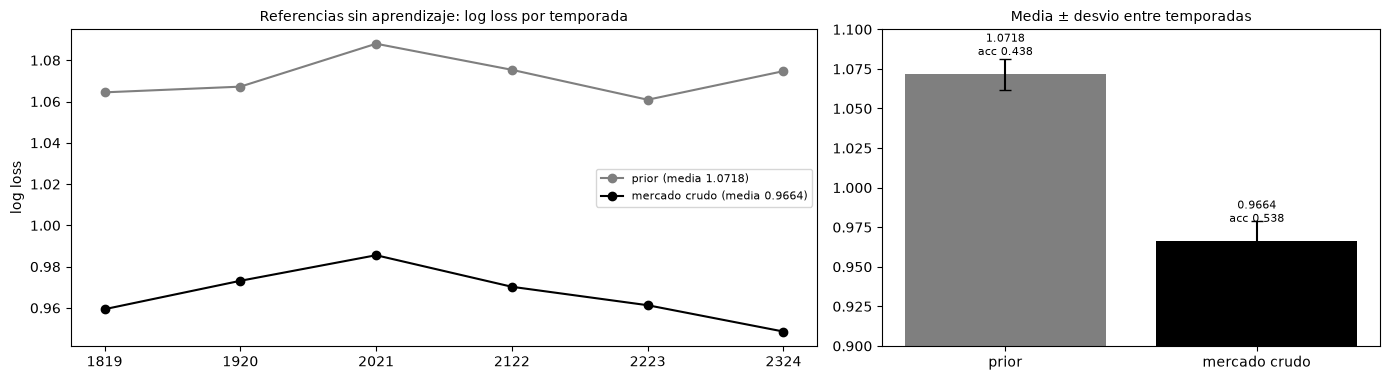

In [2]:
mk = odds[['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy()
filas = []
for s in FOLDS:
    tr, va = seas < s, seas == s
    prior = np.bincount(y[tr], minlength=3) / tr.sum()
    filas.append(dict(fold=s, modelo='prior', bloque='-', ll=log_loss(y[va], np.tile(prior, (va.sum(), 1))), acc=accuracy_score(y[va], np.full(va.sum(), prior.argmax()))))
    filas.append(dict(fold=s, modelo='mercado', bloque='-', ll=log_loss(y[va], mk[va]), acc=accuracy_score(y[va], mk[va].argmax(1))))
ref = pd.DataFrame(filas)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.9), gridspec_kw={'width_ratios': [1.5, 1]})
for m_, col_, lab in (('prior', 'tab:gray', 'prior'), ('mercado', 'k', 'mercado crudo')):
    r_ = ref[ref.modelo == m_].set_index('fold'); axs[0].plot(range(len(r_)), r_.ll, marker='o', color=col_, label=f'{lab} (media {r_.ll.mean():.4f})')
axs[0].set_xticks(range(len(FOLDS))); axs[0].set_xticklabels([int(s_) for s_ in FOLDS]); axs[0].set_ylabel('log loss'); axs[0].set_title('Referencias sin aprendizaje: log loss por temporada', fontsize=10); axs[0].legend(fontsize=8)
mm_ = ref.groupby('modelo').agg(ll=('ll', 'mean'), sd=('ll', 'std'), acc=('acc', 'mean')).loc[['prior', 'mercado']]
axs[1].bar(['prior', 'mercado crudo'], mm_.ll, yerr=mm_.sd, color=['tab:gray', 'k'], capsize=4); axs[1].set_ylim(0.9, 1.1)
for x_, (v, a_) in enumerate(zip(mm_.ll, mm_.acc)): axs[1].text(x_, v + 0.012, f'{v:.4f}\nacc {a_:.3f}', ha='center', fontsize=8)
axs[1].set_title('Media ± desvio entre temporadas', fontsize=10)
plt.tight_layout(); plt.show()

**Hallazgo.**

| Referencia | Log loss (media) | Desvío entre folds | Accuracy |
|---|---|---|---|
| Prior | 1.0718 | 0.0098 | 0.438 |
| Mercado crudo | **0.9664** | 0.0128 | 0.538 |

El mercado mejora al prior en ≈ 0.105 de log loss: es la vara contra la que se mide cualquier modelo.

**Decisión.** Reportar siempre prior y mercado junto a los modelos.

## Paso 2 — Aporte de cada bloque de features

**Qué vamos a hacer.** Añadir las features por bloques y medir el log loss fuera de muestra:

| Bloque | Contenido |
|---|---|
| **M** | Mercado (`MKT_logit`, `MKT_pD`, `MKT_margin`) |
| **M+S** | + plantilla (`DIF_sq_top11`, `HomeTeam_sq_top11_mean`) |
| **M+S+G** | + goles/puntos/portería a cero de los últimos 5 partidos (= F1) |
| **M+S+G+E** | + tiros/córners/faltas/tarjetas (= F2, solo árboles) |

**Modelos.** Regresión logística (estandarización dentro del pipeline; solo bloques sin NaN) e HistGradientBoosting (tolera NaN). Hiperparámetros **fijos y conservadores**: es una medición comparativa, no el modelo final.

**Cómo se lee.** Para cada bloque se reporta la media y el desvío del log loss entre folds, y en cuántos folds mejora respecto al bloque anterior y respecto al mercado.

{'M': 3, 'M+S': 5, 'M+S+G (F1)': 13, 'M+S+G+E (F2)': 33}


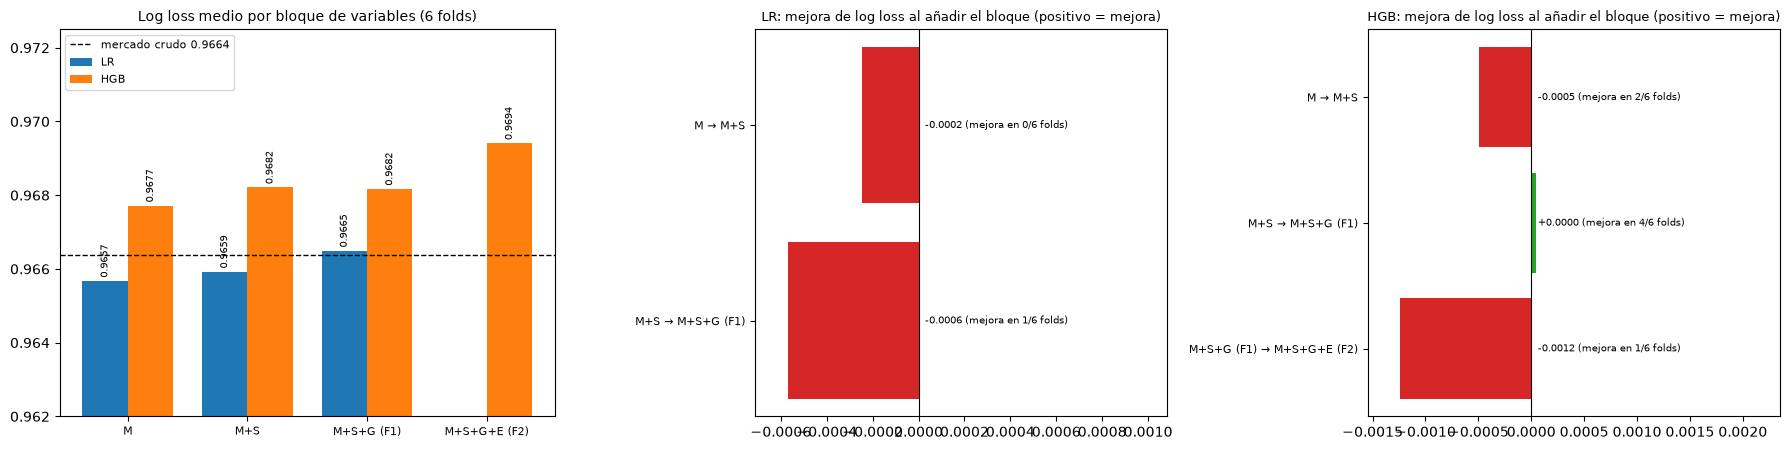

In [3]:
MKT = [f for f in ['MKT_logit', 'MKT_pD', 'MKT_margin'] if f in F2]
SQ = [f for f in ['DIF_sq_top11', 'HomeTeam_sq_top11_mean'] if f in F2]
FORMA = [f for f in F1 if f.startswith(('H_', 'A_'))]
ESTAD = [f for f in F2 if f not in F1]
BLOQUES = {'M': MKT, 'M+S': MKT + SQ, 'M+S+G (F1)': MKT + SQ + FORMA, 'M+S+G+E (F2)': MKT + SQ + FORMA + ESTAD}
print({k: len(v) for k, v in BLOQUES.items()})

def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
def hgb():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3,
                                          min_samples_leaf=100, l2_regularization=1.0, random_state=42)

filas = []
for s in FOLDS:
    tr, va = seas < s, seas == s
    for nombre, cols in BLOQUES.items():
        for modelo, fab in (('LR', lr), ('HGB', hgb)):
            if modelo == 'LR' and df[cols].isna().any().any():
                continue                                   # LR no tolera NaN: solo bloques de F1
            m = fab().fit(df.loc[tr, cols], y[tr])
            p = m.predict_proba(df.loc[va, cols])
            filas.append(dict(fold=s, modelo=modelo, bloque=nombre, ll=log_loss(y[va], p), acc=accuracy_score(y[va], p.argmax(1))))
res = pd.concat([ref, pd.DataFrame(filas)], ignore_index=True)
res.to_csv(DATA + 'ablation_results.csv', index=False)

orden = list(BLOQUES); ll_m = res[res.modelo == 'mercado'].ll.mean()
fig, axs = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={'width_ratios': [1.2, 1, 1]})
xs = np.arange(len(orden)); w = 0.38
for k, (modelo, col_) in enumerate((('LR', 'tab:blue'), ('HGB', 'tab:orange'))):
    v = [res[(res.modelo == modelo) & (res.bloque == b_)].ll.mean() if len(res[(res.modelo == modelo) & (res.bloque == b_)]) else np.nan for b_ in orden]
    sd = [res[(res.modelo == modelo) & (res.bloque == b_)].ll.std() if len(res[(res.modelo == modelo) & (res.bloque == b_)]) else np.nan for b_ in orden]
    axs[0].bar(xs + (k - 0.5) * w, v, w, color=col_, label=modelo)
    for x_, v_ in zip(xs + (k - 0.5) * w, v):
        if v_ == v_: axs[0].text(x_, v_ + 0.00015, f'{v_:.4f}', ha='center', fontsize=7, rotation=90)
axs[0].axhline(ll_m, color='k', ls='--', lw=1, label=f'mercado crudo {ll_m:.4f}'); axs[0].set_ylim(0.962, 0.9725); axs[0].set_xticks(xs); axs[0].set_xticklabels(orden, fontsize=8); axs[0].legend(fontsize=8); axs[0].set_title('Log loss medio por bloque de variables (6 folds)', fontsize=10)
for ax, modelo, col_ in ((axs[1], 'LR', 'tab:blue'), (axs[2], 'HGB', 'tab:orange')):
    labs, vals, notas = [], [], []
    for a_, b_ in zip(orden[:-1], orden[1:]):
        ra = res[(res.modelo == modelo) & (res.bloque == a_)].set_index('fold')['ll']; rb = res[(res.modelo == modelo) & (res.bloque == b_)].set_index('fold')['ll']
        if len(ra) and len(rb): d_ = ra - rb; labs.append(f'{a_} → {b_}'); vals.append(d_.mean()); notas.append(f'mejora en {int((d_ > 0).sum())}/{len(d_)} folds')
    ax.barh(range(len(vals))[::-1], vals, color=['tab:green' if v_ > 0 else 'tab:red' for v_ in vals]); ax.axvline(0, color='k', lw=0.8); ax.set_yticks(range(len(vals))[::-1]); ax.set_yticklabels(labs, fontsize=8)
    lim_ = max(abs(min(vals)), abs(max(vals))) * 1.0; ax.set_xlim(-lim_ * 1.25, lim_ * 1.9)
    for yi, v_, n_ in zip(range(len(vals))[::-1], vals, notas): ax.text(lim_ * 0.05, yi, f'{v_:+.4f} ({n_})', ha='left', va='center', fontsize=7)
    ax.set_title(f'{modelo}: mejora de log loss al añadir el bloque (positivo = mejora)', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo.** Log loss medio en los 6 folds (datos tras corregir el mapeo de clubes):

| Modelo | Bloque | Log loss | Accuracy |
|---|---|---|---|
| **LR** | **M** | **0.9657** | 0.538 |
| LR | M+S | 0.9659 | 0.539 |
| LR | M+S+G (F1) | 0.9665 | 0.539 |
| HGB | M | 0.9677 | 0.538 |
| HGB | M+S | 0.9682 | 0.537 |
| HGB | M+S+G (F1) | 0.9682 | 0.536 |
| HGB | M+S+G+E (F2) | 0.9694 | 0.538 |

1. **La plantilla (`top11_mean`) no mejora:** Δ = −0.0002 con LR (mejora en 0/6 folds) y −0.0005 con HGB (2/6).
2. **La forma (goles/puntos) no ayuda:** Δ = −0.0006 con LR (1/6 folds) y ≈ 0 con HGB (4/6).
3. **Las estadísticas de partido tampoco:** Δ = −0.0012 con HGB (1/6 folds).
4. **LR supera a HGB** en todos los bloques por ≈ 0.002.
5. **LR sobre solo el mercado mejora al mercado crudo en 0.0007** (4/6 folds): es una recalibración, no información nueva.

**Matiz.** Las diferencias entre bloques (0.0000–0.0012) son menores que la variación entre folds (± 0.013); lo relevante es el signo, sistemáticamente no positivo. Hiperparámetros fijos, sin tuning.

**Nota de datos.** Estos números ya incluyen la corrección del mapeo de clubes (110 colisiones, 9.9% de los partidos). Antes de corregirla la conclusión era la misma, pero la plantilla estaba subestimada para equipos como Arsenal o Inter.

**Decisión.** Con features agregadas de equipo (plantilla total y forma reciente) **no hay información adicional al mercado** en este esquema. Antes de entrenar más modelos, probar información *de otra naturaleza*: habilidades individuales del once titular y un target de regresión (diferencia de goles).

## Paso 3 — Habilidades individuales del once titular (clasificación)

**Qué vamos a hacer.** Añadir las 33 features `SK_*` (diferencia local − visitante de las habilidades del once titular, construidas en `02_feature.ipynb`, Paso 10) a los bloques anteriores y repetir la validación temporal:

| Bloque | Contenido |
|---|---|
| **M** | Mercado |
| **M+SK** | Mercado + 33 habilidades |
| **M+S+G+SK** | Mercado + plantilla + forma (F1) + habilidades |

Se prueban regresión logística con dos regularizaciones (`C = 1` y `C = 0.05`, porque son 36–46 features) e HistGradientBoosting.

**Sensibilidad a 2024/25.** El snapshot FC25 es de fin de temporada (julio de 2025, sin fichajes de verano), por lo que esa temporada podría tener cierto *look-ahead*. En una versión previa se comprobó que el aporte de las habilidades era el mismo con y sin ella. Con el test holdout, 2024/25 y 2025/26 **ya no entran en el entrenamiento ni en la validación**, así que ese posible *look-ahead* no puede afectar a ningún resultado de este cuaderno; solo podría afectar a la evaluación final en test, donde las habilidades no se usan (el modelo final usa solo las cuotas).

In [4]:
sk = pd.read_csv(DATA + 'dataset_skills.csv')
assert (sk[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
SK = fs['SK_habilidades']
Xall = pd.concat([df.reset_index(drop=True), sk[SK]], axis=1)
GD = sk['GD'].to_numpy(float)
print('habilidades:', len(SK), '| filas:', len(Xall), '| NaN en SK:', int(sk[SK].isna().sum().sum()))

def lr_c(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
MODELOS_CLAS = {'LR C=1': lambda: lr_c(1.0), 'LR C=0.05': lambda: lr_c(0.05), 'HGB': hgb}
BLOQ_SK = {'M': MKT, 'M+SK': MKT + SK, 'M+S+G+SK': MKT + SQ + FORMA + SK}

def cv_clas():
    filas = []
    for s in FOLDS:
        tr, va = seas < s, seas == s
        for nombre, cols in BLOQ_SK.items():
            for modelo, fab in MODELOS_CLAS.items():
                m = fab().fit(Xall.loc[tr, cols], y[tr])
                p = m.predict_proba(Xall.loc[va, cols])
                filas.append(dict(fold=int(s), modelo=modelo, bloque=nombre, ll=log_loss(y[va], p), acc=accuracy_score(y[va], p.argmax(1))))
    return pd.DataFrame(filas)

con = cv_clas()
orden_b = list(BLOQ_SK)
t = con.groupby(['modelo', 'bloque']).ll.mean().round(4)
t = t.reindex(pd.MultiIndex.from_product([list(MODELOS_CLAS), orden_b], names=['modelo', 'bloque']))
print('Log loss medio (menor es mejor). Mercado crudo (6 folds):', round(ref[ref.modelo == 'mercado'].ll.mean(), 4))
print(t.to_string())

print('\nAporte de las habilidades = log loss(M) - log loss(M+SK); positivo = mejora:')
for modelo in MODELOS_CLAS:
    a = con[(con.modelo == modelo) & (con.bloque == 'M')].set_index('fold').ll
    b = con[(con.modelo == modelo) & (con.bloque == 'M+SK')].set_index('fold').ll
    dd = a - b
    print(f'  {modelo:<10}: delta = {dd.mean():+.4f} | mejora en {(dd > 0).sum()}/{len(dd)} folds')
con.assign(variante='con').to_csv(DATA + 'skills_clasificacion.csv', index=False)

habilidades: 33 | filas: 36119 | NaN en SK: 0


Log loss medio (menor es mejor). Mercado crudo (6 folds): 0.9664
modelo     bloque  
LR C=1     M           0.9657
           M+SK        0.9675
           M+S+G+SK    0.9683
LR C=0.05  M           0.9657
           M+SK        0.9675
           M+S+G+SK    0.9682
HGB        M           0.9677
           M+SK        0.9691
           M+S+G+SK    0.9693

Aporte de las habilidades = log loss(M) - log loss(M+SK); positivo = mejora:
  LR C=1    : delta = -0.0019 | mejora en 0/6 folds
  LR C=0.05 : delta = -0.0019 | mejora en 0/6 folds
  HGB       : delta = -0.0013 | mejora en 0/6 folds


**Hallazgo.** Log loss medio en los 6 folds (menor es mejor; mercado crudo: 0.9664):

| Modelo | Bloque | Log loss |
|---|---|---|
| LR C=1 | M | **0.9657** |
| LR C=1 | M+SK | 0.9675 |
| LR C=1 | M+S+G+SK | 0.9683 |
| LR C=0.05 | M | 0.9657 |
| LR C=0.05 | M+SK | 0.9675 |
| LR C=0.05 | M+S+G+SK | 0.9682 |
| HGB | M | 0.9677 |
| HGB | M+SK | 0.9691 |
| HGB | M+S+G+SK | 0.9693 |

- **Las habilidades empeoran el log loss:** Δ = −0.0019 con LR (no mejoran en ninguno de los 6 folds) y −0.0013 con HGB (0/6). `C = 0.05` da lo mismo que `C = 1`.
- Añadir además plantilla y forma (M+S+G+SK) empeora un poco más.
- **2024/25 ya no interviene:** queda en el test holdout, de modo que el posible *look-ahead* del snapshot de fin de temporada no afecta a esta comparación.

**Interpretación.** Las 33 habilidades están muy correlacionadas entre sí y con el `overall` (media |r| = 0.73) y su información ya está en las cuotas: añaden varianza sin sesgo que corregir.

**Decisión.** Las habilidades **no** entran en los modelos de clasificación finales. Se conservan solo para los experimentos de regresión y apilado (Pasos 4–5), que miden su información de otra manera.

## Paso 4 — Regresión de la diferencia de goles

**Qué vamos a hacer.** Cambiar el *target*: en vez de H/D/A, predecir `GD = goles local − goles visitante` (regresión), como en Stübinger et al. La diferencia de goles contiene más información por partido que el signo (un 4–0 y un 1–0 son ambos "H").

**Modelos** (los del paper, salvo SVM, que con 30 mil filas es demasiado lento):

- **LIN:** regresión lineal con estandarización (*LIR* del paper).
- **RF:** Random Forest (100 árboles, `min_samples_leaf = 50`, `max_features = 0.33`).
- **HGB:** HistGradientBoosting (equivalente al *boosting* del paper).
- **ALL:** promedio de los tres (el *ensemble* del paper).

**Bloques de features.**

| Bloque | Contenido | Qué responde |
|---|---|---|
| **SK** | 33 habilidades | ¿Qué tan bien predicen la diferencia de goles *por sí solas*? |
| **S+G+SK** | plantilla + forma + habilidades (sin mercado) | ¿Y con todo lo no-mercado? |
| **M+SK** | mercado + habilidades | ¿Qué hace el modelo cuando ve las cuotas? |

**Cómo se convierte `ŷ` en probabilidades 1X2.** Con una regresión logística multinomial sobre `ŷ` entrenada en la **temporada inmediatamente anterior** a la de validación (con un modelo que solo vio temporadas previas a esa). Así no hay fuga y no se usa una predicción *in-sample* sobrecalibrada.

**Métricas.** RMSE y MAE de `GD` (referencias: predecir la media del entrenamiento y regresar solo sobre el mercado) y log loss de las probabilidades derivadas.

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

def lin():
    return make_pipeline(StandardScaler(), LinearRegression())
def rf():
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_features=0.33, max_samples=0.5, n_jobs=-1, random_state=42)
def hgbr():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=200, max_depth=3, min_samples_leaf=100, l2_regularization=1.0, random_state=42)

REG = {'LIN': lin, 'RF': rf, 'HGB': hgbr}
BLOQ_REG = {'SK': SK, 'S+G+SK': SQ + FORMA + SK, 'M+SK': MKT + SK}
MKT_MIN = ['MKT_logit', 'MKT_pD']
temporadas = sorted(df['Season'].unique())
prev_de = {s: temporadas[temporadas.index(s) - 1] for s in temporadas[1:]}

def pred_reg(s, cols, fab):
    """Devuelve (yhat de la temporada anterior, yhat de la temporada s). El modelo de la anterior solo ve temporadas previas a ella."""
    p = prev_de[s]
    tr_c, ca = seas < p, seas == p
    tr, va = seas < s, seas == s
    m_c = fab().fit(Xall.loc[tr_c, cols], GD[tr_c])
    m = fab().fit(Xall.loc[tr, cols], GD[tr])
    return ca, m_c.predict(Xall.loc[ca, cols]), va, m.predict(Xall.loc[va, cols])

def ll_desde(feats_cal, y_cal, feats_va, y_va):
    c = LogisticRegression(C=10.0, max_iter=2000).fit(feats_cal, y_cal)
    return log_loss(y_va, c.predict_proba(feats_va), labels=[0, 1, 2])

mk_l = Xall['MKT_logit'].to_numpy()
filas, preds = [], {}
for s in FOLDS:
    va = seas == s
    tr = seas < s
    # referencias de regresion
    mu = GD[tr].mean()
    filas.append(dict(fold=int(s), modelo='media', bloque='-', rmse=np.sqrt(np.mean((GD[va] - mu) ** 2)), mae=np.mean(np.abs(GD[va] - mu)), ll_y=np.nan, ll_stack=np.nan))
    for nombre, cols in {'M (mercado)': MKT_MIN}.items():
        ca, yc, va_, yv = pred_reg(s, cols, lin)
        filas.append(dict(fold=int(s), modelo='LIN', bloque=nombre, rmse=np.sqrt(np.mean((GD[va_] - yv) ** 2)), mae=np.mean(np.abs(GD[va_] - yv)),
                          ll_y=ll_desde(yc.reshape(-1, 1), y[ca], yv.reshape(-1, 1), y[va_]), ll_stack=np.nan))
    for nombre, cols in BLOQ_REG.items():
        guardado = {}
        for modelo, fab in REG.items():
            ca, yc, va_, yv = pred_reg(s, cols, fab)
            guardado[modelo] = (yc, yv)
        guardado['ALL'] = (np.mean([guardado[m][0] for m in REG], axis=0), np.mean([guardado[m][1] for m in REG], axis=0))
        for modelo, (yc, yv) in guardado.items():
            ll_y = ll_desde(yc.reshape(-1, 1), y[ca], yv.reshape(-1, 1), y[va_])
            # apilado con el mercado: P(FTR | MKT_logit, yhat) vs P(FTR | MKT_logit)
            ll_st = ll_desde(np.c_[mk_l[ca], yc], y[ca], np.c_[mk_l[va_], yv], y[va_])
            filas.append(dict(fold=int(s), modelo=modelo, bloque=nombre, rmse=np.sqrt(np.mean((GD[va_] - yv) ** 2)), mae=np.mean(np.abs(GD[va_] - yv)), ll_y=ll_y, ll_stack=ll_st))
        preds[(s, nombre)] = guardado
    # referencia de apilado: solo mercado
    ll_m = ll_desde(mk_l[ca].reshape(-1, 1), y[ca], mk_l[va_].reshape(-1, 1), y[va_])
    filas.append(dict(fold=int(s), modelo='solo mercado', bloque='-', rmse=np.nan, mae=np.nan, ll_y=np.nan, ll_stack=ll_m))
reg = pd.DataFrame(filas)
reg.to_csv(DATA + 'skills_regresion.csv', index=False)

res_r = reg.groupby(['modelo', 'bloque'], sort=False).agg(rmse=('rmse', 'mean'), mae=('mae', 'mean'), ll_solo_yhat=('ll_y', 'mean')).round(4)
print(res_r.to_string())

                            rmse     mae  ll_solo_yhat
modelo       bloque                                   
media        -            1.8564  1.4422           NaN
LIN          M (mercado)  1.6251  1.2578        0.9683
             SK           1.6860  1.3065        0.9954
RF           SK           1.6843  1.3028        0.9945
HGB          SK           1.6854  1.3041        0.9951
ALL          SK           1.6834  1.3029        0.9944
LIN          S+G+SK       1.6703  1.2944        0.9895
RF           S+G+SK       1.6752  1.2963        0.9907
HGB          S+G+SK       1.6732  1.2951        0.9899
ALL          S+G+SK       1.6702  1.2931        0.9889
LIN          M+SK         1.6267  1.2593        0.9693
RF           M+SK         1.6310  1.2636        0.9714
HGB          M+SK         1.6280  1.2609        0.9700
ALL          M+SK         1.6270  1.2600        0.9695
solo mercado -               NaN     NaN           NaN


**Hallazgo.** Promedio en los 6 folds:

| Modelo | Bloque | RMSE de GD | MAE | Log loss con solo `ŷ` |
|---|---|---|---|---|
| (predecir la media) | — | 1.8564 | 1.4422 | — |
| LIN | solo mercado | **1.6251** | 1.2578 | **0.9683** |
| LIN | SK | 1.6860 | 1.3065 | 0.9954 |
| ALL | SK | 1.6834 | 1.3029 | 0.9944 |
| LIN | S+G+SK | 1.6703 | 1.2944 | 0.9895 |
| ALL | S+G+SK | 1.6702 | 1.2931 | 0.9889 |
| LIN | M+SK | 1.6267 | 1.2593 | 0.9693 |
| ALL | M+SK | 1.6270 | 1.2600 | 0.9695 |

1. **Las habilidades sí contienen información sobre los goles.** Solas bajan el RMSE de 1.856 a 1.683 (−9.3%) y producen probabilidades 1X2 con log loss 0.994, claramente mejores que el prior (1.0718).
2. **Pero el mercado predice mejor:** una regresión lineal sobre solo `MKT_logit` y `MKT_pD` da RMSE 1.625 (log loss 0.968), mejor que cualquier bloque sin cuotas (el mejor, S+G+SK con ALL, 1.670).
3. **Añadir habilidades al mercado no ayuda:** 1.6267–1.6310 vs 1.6251.
4. **Los tres modelos del paper rinden casi igual** (LIN ≈ RF ≈ HGB; el ensemble ALL mejora apenas 0.0001–0.0009 al mejor individual, y con M+SK no lo mejora): la relación entre estas features y la diferencia de goles es prácticamente lineal.

**Decisión.** La regresión de la diferencia de goles es válida y más informativa por partido, pero con estas features **no supera** al mercado. Falta comprobar si `ŷ` aporta algo *sobre* el mercado (Paso 5).

## Paso 5 — ¿Las habilidades aportan información sobre el mercado?

**Qué vamos a hacer.** Es la pregunta central del proyecto. Para cada predicción de diferencia de goles `ŷ` (que **no** vio las cuotas, bloques `SK` y `S+G+SK`) comparar:

- `P(FTR | MKT_logit)`: el mercado solo, con el mismo calibrador;
- `P(FTR | MKT_logit, ŷ)`: el mercado **más** la predicción de goles.

Si `ŷ` contiene información que las cuotas no tienen, el segundo log loss debe ser menor. Ambas regresiones logísticas se entrenan en la misma temporada de calibración, así que la comparación es limpia.

**Cómo se lee.** `delta = ll(solo mercado) − ll(mercado + ŷ)`; positivo = la predicción de goles aporta.

In [6]:
base_m = reg[reg.modelo == 'solo mercado'].set_index('fold').ll_stack
print(f'Log loss del apilado con solo mercado (media {len(base_m)} folds): {base_m.mean():.4f}\n')
filas_s = []
for modelo in list(REG) + ['ALL']:
    for nombre in BLOQ_REG:
        r = reg[(reg.modelo == modelo) & (reg.bloque == nombre)].set_index('fold')
        d = base_m - r.ll_stack
        filas_s.append(dict(modelo=modelo, bloque=nombre, ll_mercado_mas_yhat=r.ll_stack.mean(), delta=d.mean(), folds_mejora=f'{(d > 0).sum()}/{len(d)}', rmse=r.rmse.mean()))
st = pd.DataFrame(filas_s).round(4)
print(st.to_string(index=False))

# correlacion de la prediccion de goles sin mercado con la implicita en el mercado (como medida de redundancia)
print('\nCorrelacion entre yhat (S+G+SK, ALL) y MKT_logit en la validacion:')
cors = []
for s in FOLDS:
    yv = preds[(s, 'S+G+SK')]['ALL'][1]
    cors.append(np.corrcoef(yv, mk_l[seas == s])[0, 1])
print('  media:', round(float(np.mean(cors)), 3), '| por fold:', [round(float(c), 2) for c in cors])

Log loss del apilado con solo mercado (media 6 folds): 0.9682

modelo bloque  ll_mercado_mas_yhat   delta folds_mejora   rmse
   LIN     SK               0.9684 -0.0003          1/6 1.6860
   LIN S+G+SK               0.9683 -0.0002          2/6 1.6703
   LIN   M+SK               0.9683 -0.0002          1/6 1.6267
    RF     SK               0.9685 -0.0003          2/6 1.6843
    RF S+G+SK               0.9684 -0.0002          2/6 1.6752
    RF   M+SK               0.9683 -0.0001          2/6 1.6310
   HGB     SK               0.9685 -0.0003          2/6 1.6854
   HGB S+G+SK               0.9683 -0.0002          2/6 1.6732
   HGB   M+SK               0.9683 -0.0001          2/6 1.6280
   ALL     SK               0.9685 -0.0003          2/6 1.6834
   ALL S+G+SK               0.9683 -0.0002          2/6 1.6702
   ALL   M+SK               0.9682 -0.0000          2/6 1.6270

Correlacion entre yhat (S+G+SK, ALL) y MKT_logit en la validacion:
  media: 0.912 | por fold: [0.92, 0.91, 0.91, 0.91

**Hallazgo.** El log loss del apilado con solo el mercado es 0.9682 (el calibrador usa solo la temporada anterior; por eso es algo mayor que el 0.9657 de la regresión logística entrenada con todo el historial).

| Predicción de goles `ŷ` | Log loss de `MKT_logit` + `ŷ` | delta | Folds en que mejora |
|---|---|---|---|
| ALL, SK | 0.9685 | −0.0003 | 2/6 |
| ALL, S+G+SK | 0.9683 | −0.0002 | 2/6 |
| ALL, M+SK | 0.9682 | 0.0000 | 2/6 |
| LIN, SK | 0.9684 | −0.0003 | 1/6 |
| RF, SK | 0.9685 | −0.0003 | 2/6 |
| HGB, SK | 0.9685 | −0.0003 | 2/6 |

- **Ninguna predicción de goles mejora al mercado:** todos los *delta* están entre −0.0003 y 0.0000.
- **Redundancia:** la correlación entre `ŷ` (S+G+SK) y `MKT_logit` es **0.91** (0.91–0.92 en todos los folds). La predicción de goles construida sin cuotas reproduce casi la misma ordenación de equipos que el mercado.

**Decisión / respuesta a la pregunta.** **Con estos datos, las habilidades individuales no aportan información adicional a las cuotas**, ni en clasificación ni en regresión. La temporada 2024/25 (con el posible *look-ahead* del snapshot) ya no interviene: está en el test holdout. Es un resultado negativo bien sustentado.

## Paso 6a — Selección de hiperparámetros de LR, HGB, RF y HGB de regresión (antes de fijarlos)

**Qué vamos a hacer.** Con los bloques y los modelos ya comparados (Pasos 2 a 5), elegir los hiperparámetros de los cuatro modelos base que usan los pasos siguientes y los demás cuadernos, con un procedimiento explícito, no a ojo:

1. **Rejilla corta** por modelo (valores en escala logarítmica o de complejidad creciente).
2. **Validación temporal** dentro de la ventana de ajuste: para cada temporada de ajuste (2016/17 y 2017/18) se entrena con todas las anteriores y se mide el error en esa temporada.
3. **Criterio:** menor log loss (clasificación) o menor RMSE (regresión), promediado en las dos temporadas.
4. **Desempate:** ante diferencias menores a 0.0005 en log loss (o 0.002 en RMSE), la configuración **más simple** (menos profundidad, menos iteraciones, más regularización).
5. Los valores elegidos se **congelan** y se usan en los folds de evaluación, que no se tocan.

| Modelo | Bloque | Rejilla |
|---|---|---|
| LR (clasificación) | F1 | `C ∈ {0.01, 0.05, 0.2, 1, 5}` |
| HGB (clasificación) | F1 | `learning_rate ∈ {0.03, 0.1}`, `max_depth ∈ {2, 3, 4}`, `min_samples_leaf ∈ {50, 200}`, `max_iter ∈ {100, 300}` |
| RF (regresión de GD) | sin cuotas | `min_samples_leaf ∈ {20, 50, 100}`, `max_features ∈ {0.2, 0.33, 0.5}` |
| HGB (regresión de GD) | sin cuotas | `learning_rate ∈ {0.03, 0.1}`, `max_depth ∈ {2, 3, 4}`, `min_samples_leaf ∈ {50, 200}`, `max_iter ∈ {100, 300}` |

**Limitación.** La ventana de ajuste es pequeña (≈ 6,000 partidos de validación y 6–9 mil de entrenamiento), así que la selección es ruidosa: se espera que varias configuraciones queden casi empatadas, y por eso el desempate favorece la simplicidad.

In [7]:
from itertools import product
from sklearn.ensemble import RandomForestRegressor
TUNE = [1617, 1718]
X = Xall                                     # todas las variables (df + habilidades)
NM = SQ + FORMA + SK                         # bloque sin cuotas: plantilla + forma + habilidades
def elegir(resultados, clave, tol):
    df_r = pd.DataFrame(resultados).sort_values(clave).reset_index(drop=True)
    mejor = df_r[clave].iloc[0]
    cercanas = df_r[df_r[clave] <= mejor + tol].copy()
    # desempate por simplicidad: menos profundidad / iteraciones, mas hoja minima / regularizacion
    orden = [c for c in ('max_depth', 'max_iter', 'C') if c in cercanas]
    asc = [True] * len(orden)
    if 'C' in orden:
        asc[orden.index('C')] = True
    cercanas = cercanas.sort_values(orden + [clave], ascending=asc + [True])
    return cercanas.iloc[0].to_dict(), df_r

def ll_tune(make, cols, params):
    out = []
    for s in TUNE:
        tr, va = seas < s, seas == s
        m = make(**params).fit(X.loc[tr, cols], y[tr])
        out.append(log_loss(y[va], m.predict_proba(X.loc[va, cols])))
    return float(np.mean(out))

def rmse_tune(make, cols, params):
    out = []
    for s in TUNE:
        tr, va = seas < s, seas == s
        m = make(**params).fit(X.loc[tr, cols], GD[tr])
        out.append(float(np.sqrt(np.mean((GD[va] - m.predict(X.loc[va, cols])) ** 2))))
    return float(np.mean(out))

mk_lr = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
mk_hgbc = lambda learning_rate, max_depth, min_samples_leaf, max_iter: HistGradientBoostingClassifier(
    learning_rate=learning_rate, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_iter=max_iter, l2_regularization=1.0, random_state=42)
mk_rf = lambda min_samples_leaf, max_features: RandomForestRegressor(
    n_estimators=100, min_samples_leaf=min_samples_leaf, max_features=max_features, max_samples=0.5, n_jobs=-1, random_state=42)
mk_hgbr = lambda learning_rate, max_depth, min_samples_leaf, max_iter: HistGradientBoostingRegressor(
    learning_rate=learning_rate, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_iter=max_iter, l2_regularization=1.0, random_state=42)

BEST, TABLAS = {}, {}
# 1) LR clasificacion
res = [dict(C=C, ll=ll_tune(mk_lr, F1, dict(C=C))) for C in (0.01, 0.05, 0.2, 1, 5)]
BEST['LR_clas'], TABLAS['LR_clas'] = elegir(res, 'll', 0.0005)
# 2) HGB clasificacion
g = list(product((0.03, 0.1), (2, 3, 4), (50, 200), (100, 300)))
res = [dict(learning_rate=a, max_depth=b, min_samples_leaf=c, max_iter=d, ll=ll_tune(mk_hgbc, F1, dict(learning_rate=a, max_depth=b, min_samples_leaf=c, max_iter=d))) for a, b, c, d in g]
BEST['HGB_clas'], TABLAS['HGB_clas'] = elegir(res, 'll', 0.0005)
# 3) RF regresion (sin cuotas)
res = [dict(min_samples_leaf=a, max_features=b, rmse=rmse_tune(mk_rf, NM, dict(min_samples_leaf=a, max_features=b))) for a, b in product((20, 50, 100), (0.2, 0.33, 0.5))]
BEST['RF_reg'], TABLAS['RF_reg'] = elegir(res, 'rmse', 0.002)
# 4) HGB regresion (sin cuotas)
res = [dict(learning_rate=a, max_depth=b, min_samples_leaf=c, max_iter=d, rmse=rmse_tune(mk_hgbr, NM, dict(learning_rate=a, max_depth=b, min_samples_leaf=c, max_iter=d))) for a, b, c, d in g]
BEST['HGB_reg'], TABLAS['HGB_reg'] = elegir(res, 'rmse', 0.002)

for k, t in TABLAS.items():
    clave = 'll' if 'll' in t else 'rmse'
    print(f'\n== {k}: {len(t)} configuraciones | mejor {clave} = {t[clave].min():.4f} | peor = {t[clave].max():.4f} | rango = {t[clave].max() - t[clave].min():.4f}')
    print(t.head(3).round(4).to_string(index=False))
    print('   ELEGIDA:', {a: (round(b, 4) if isinstance(b, float) else b) for a, b in BEST[k].items()})
json.dump({k: {a: (float(b) if isinstance(b, (float, np.floating)) else int(b)) for a, b in v.items()} for k, v in BEST.items()}, open(DATA + 'hiperparametros.json', 'w'), indent=1)


== LR_clas: 5 configuraciones | mejor ll = 0.9429 | peor = 0.9434 | rango = 0.0005
  C     ll
0.2 0.9429
1.0 0.9429
5.0 0.9429
   ELEGIDA: {'C': 0.05, 'll': 0.9429}

== HGB_clas: 24 configuraciones | mejor ll = 0.9481 | peor = 1.0240 | rango = 0.0760
 learning_rate  max_depth  min_samples_leaf  max_iter     ll
          0.03          2                50       100 0.9481
          0.03          2               200       100 0.9483
          0.03          3               200       100 0.9508
   ELEGIDA: {'learning_rate': 0.03, 'max_depth': 2.0, 'min_samples_leaf': 50.0, 'max_iter': 100.0, 'll': 0.9481}

== RF_reg: 9 configuraciones | mejor rmse = 1.6490 | peor = 1.6523 | rango = 0.0033
 min_samples_leaf  max_features   rmse
               20           0.5 1.6490
               50           0.5 1.6492
              100           0.5 1.6500
   ELEGIDA: {'min_samples_leaf': 20.0, 'max_features': 0.5, 'rmse': 1.649}

== HGB_reg: 24 configuraciones | mejor rmse = 1.6501 | peor = 1.6789 | ran

**Qué encontramos.** Procedimiento: rejilla corta → validación temporal en 2016/17 y 2017/18 → menor log loss/RMSE → desempate por simplicidad.

| Modelo | Configuraciones | Mejor | Peor | Rango | **Elegida** |
|---|---|---|---|---|---|
| LR (clasificación, F1) | 5 | 0.9429 | 0.9434 | 0.0005 | `C = 0.05` |
| HGB (clasificación, F1) | 24 | 0.9481 | 1.0240 | 0.0760 | `learning_rate = 0.03`, `max_depth = 2`, `min_samples_leaf = 50`, `max_iter = 100` |
| RF (GD, sin cuotas) | 9 | 1.6490 | 1.6523 | 0.0033 | `min_samples_leaf = 20`, `max_features = 0.5` |
| HGB (GD, sin cuotas) | 24 | 1.6501 | 1.6789 | 0.0287 | `learning_rate = 0.1`, `max_depth = 2`, `min_samples_leaf = 50`, `max_iter = 100` |

- **LR y RF son insensibles:** el rango entre la mejor y la peor configuración es 0.0005 de log loss y 0.003 de RMSE. Cualquier valor razonable da lo mismo.
- **HGB sí es sensible** (rango 0.076 en log loss), y siempre prefiere **árboles muy poco profundos** (`max_depth = 2`) y pocas iteraciones: con datos tan ruidosos, la complejidad sobreajusta. Esto es coherente con que la relación sea casi lineal (Paso 4 de este cuaderno: LIN ≈ RF ≈ HGB).
- La selección es ruidosa (ventana pequeña): por eso se aplicó el desempate por simplicidad (por ejemplo, en HGB de regresión se eligió 100 iteraciones en lugar de 300 por una diferencia de 0.0007 de RMSE).

**Qué significa para nuestro caso.** Los modelos que se comparan después no dependen de una elección a ojo: usan valores elegidos solo con las temporadas 2016/17 y 2017/18, que no se evalúan. Que LR y RF sean insensibles y que HGB prefiera árboles de profundidad 2 con pocas iteraciones es otra señal de que la relación entre el precio y el resultado es casi lineal.

**Decisión.** Congelar estos valores (guardados en `hiperparametros.json`) para todos los folds de evaluación y para los cuadernos siguientes.

## Paso 6 — Selección de hiperparámetros de SVM, XGBoost y MLP

**Qué vamos a hacer.** Elegir los hiperparámetros de los tres modelos que faltan con **el mismo procedimiento** que en el Paso 6a:

1. Rejilla corta por modelo.
2. Validación temporal en la **ventana de ajuste** (2016/17 y 2017/18), disjunta de los folds de evaluación (2018/19–2023/24).
3. Criterio: menor log loss. Desempate: la configuración **más simple** si la diferencia es < 0.0005.
4. Valores congelados.

| Modelo | Features | Rejilla |
|---|---|---|
| **SVM** (kernel RBF, probabilidades por escalamiento de Platt interno) | F1, estandarizadas | `C ∈ {0.1, 1, 10}`, `gamma ∈ {0.01, 0.05, 0.2}` |
| **XGBoost** | F2 (tolera NaN) | `learning_rate ∈ {0.03, 0.1}`, `max_depth ∈ {2, 3, 4}`, `n_estimators ∈ {100, 300}`, `min_child_weight ∈ {5, 30}` |
| **MLP** (ReLU, *early stopping*) | F1, estandarizadas | capas `∈ {(16), (32, 16)}`, `alpha ∈ {0.001, 0.01, 0.1, 1}` |

**Notas de diseño.**

- El SVM con kernel RBF escala de forma cuadrática con las filas: se entrena con las **9,000 filas más recientes** (≈ 3 temporadas) en la selección y en la evaluación, para que sea tratable y comparable.
- El MLP es estocástico: cada configuración se promedia sobre **3 semillas** (en la selección y en la evaluación).
- Las referencias (LR sobre cuotas y HGB) usan los valores elegidos en el Paso 6a (`hiperparametros.json`).

In [8]:
from itertools import product
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=FutureWarning)   # SVC(probability=True) esta deprecado desde scikit-learn 1.9 (se retira en 1.11)
HP = json.load(open(DATA + 'hiperparametros.json'))
X1 = Xall                                   # DataFrame con todas las features (F1 sin NaN, F2 con NaN)
X2 = Xall[F2].to_numpy(float)               # XGBoost tolera NaN
XF1 = Xall[F1].to_numpy(float)              # F1: sin NaN, para SVM y MLP
TUNE = [1617, 1718]
assert not set(TUNE) & set(int(s) for s in FOLDS)
CAP_SVM = 9000

def cap(tr_mask, n=CAP_SVM):
    ix = np.where(tr_mask)[0]
    return ix[-n:] if len(ix) > n else ix

def svm_fab(C, gamma):
    return make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma, kernel='rbf', probability=True, random_state=42))
def mlp_fab(hidden, alpha, seed=0):
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, activation='relu', max_iter=300, early_stopping=True,
                                                         validation_fraction=0.1, n_iter_no_change=15, random_state=seed))
def xgb_fab(learning_rate, max_depth, n_estimators, min_child_weight):
    return XGBClassifier(objective='multi:softprob', tree_method='hist', learning_rate=learning_rate, max_depth=max_depth, n_estimators=n_estimators,
                         min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, n_jobs=8)

def prob_mlp(hidden, alpha, Xtr, ytr, Xva, seeds=(0, 1, 2)):
    return np.mean([mlp_fab(hidden, alpha, s).fit(Xtr, ytr).predict_proba(Xva) for s in seeds], axis=0)

def ll_tune(fn):
    out = []
    for s in TUNE:
        tr, va = seas < s, seas == s
        out.append(log_loss(y[va], fn(tr, va), labels=[0, 1, 2]))
    return float(np.mean(out))

def elegir(res, simple_keys):
    t = pd.DataFrame(res).sort_values('ll').reset_index(drop=True)
    cerca = t[t.ll <= t.ll.iloc[0] + 0.0005]
    return cerca.sort_values(simple_keys + ['ll'], ascending=[True] * len(simple_keys) + [True]).iloc[0].to_dict(), t

BEST6, TAB6 = {}, {}
# SVM
res = []
for C, g in product((0.1, 1, 10), (0.01, 0.05, 0.2)):
    res.append(dict(C=C, gamma=g, ll=ll_tune(lambda tr, va: svm_fab(C, g).fit(XF1[cap(tr)], y[cap(tr)]).predict_proba(XF1[va]))))
BEST6['SVM'], TAB6['SVM'] = elegir(res, ['gamma', 'C'])
# XGBoost
res = []
for lr_, d_, n_, w_ in product((0.03, 0.1), (2, 3, 4), (100, 300), (5, 30)):
    res.append(dict(learning_rate=lr_, max_depth=d_, n_estimators=n_, min_child_weight=w_,
                    ll=ll_tune(lambda tr, va: xgb_fab(lr_, d_, n_, w_).fit(X2[tr], y[tr]).predict_proba(X2[va]))))
BEST6['XGB'], TAB6['XGB'] = elegir(res, ['max_depth', 'n_estimators'])
# MLP
res = []
for h_, a_ in product(((16,), (32, 16)), (0.001, 0.01, 0.1, 1.0)):
    res.append(dict(hidden=str(h_), alpha=a_, ll=ll_tune(lambda tr, va: prob_mlp(h_, a_, XF1[tr], y[tr], XF1[va]))))
t6 = pd.DataFrame(res)
t6['n_capas'] = t6.hidden.map(lambda s: len(eval(s)))
BEST6['MLP'] = (lambda d: d[d.ll <= d.ll.min() + 0.0005].sort_values(['n_capas', 'alpha'], ascending=[True, False]).iloc[0].to_dict())(t6)
TAB6['MLP'] = t6.sort_values('ll').reset_index(drop=True)

for k, t in TAB6.items():
    print(f'\n== {k}: {len(t)} configuraciones | mejor ll = {t.ll.min():.4f} | peor = {t.ll.max():.4f} | rango = {t.ll.max() - t.ll.min():.4f}')
    print(t.head(3).round(4).to_string(index=False))
    print('   ELEGIDA:', {a: (round(b, 4) if isinstance(b, float) else b) for a, b in BEST6[k].items() if a != 'n_capas'})
HP6 = {'SVM': {k: float(v) for k, v in BEST6['SVM'].items()}, 'XGB': {k: (float(v)) for k, v in BEST6['XGB'].items()},
       'MLP': {'hidden': BEST6['MLP']['hidden'], 'alpha': float(BEST6['MLP']['alpha']), 'll': float(BEST6['MLP']['ll'])}}
json.dump(HP6, open(DATA + 'hiperparametros_modelos.json', 'w'), indent=1)


== SVM: 9 configuraciones | mejor ll = 0.9704 | peor = 1.0227 | rango = 0.0522
   C  gamma     ll
 0.1   0.01 0.9704
 1.0   0.01 0.9708
10.0   0.01 0.9715
   ELEGIDA: {'C': 0.1, 'gamma': 0.01, 'll': 0.9704}

== XGB: 24 configuraciones | mejor ll = 0.9487 | peor = 0.9917 | rango = 0.0429
 learning_rate  max_depth  n_estimators  min_child_weight     ll
          0.03          2           100                 5 0.9487
          0.03          2           100                30 0.9489
          0.03          2           300                 5 0.9491
   ELEGIDA: {'learning_rate': 0.03, 'max_depth': 2.0, 'n_estimators': 100.0, 'min_child_weight': 5.0, 'll': 0.9487}

== MLP: 8 configuraciones | mejor ll = 0.9457 | peor = 0.9482 | rango = 0.0025
  hidden  alpha     ll  n_capas
(32, 16)  0.001 0.9457        2
(32, 16)  1.000 0.9461        2
   (16,)  1.000 0.9463        1
   ELEGIDA: {'hidden': '(32, 16)', 'alpha': 1.0, 'll': 0.9461}


**Hallazgo.**

| Modelo | Configuraciones | Mejor | Peor | Rango | **Elegida** |
|---|---|---|---|---|---|
| SVM (RBF) | 9 | 0.9704 | 1.0227 | 0.0522 | `C = 0.1`, `gamma = 0.01` |
| XGBoost | 24 | 0.9487 | 0.9917 | 0.0429 | `learning_rate = 0.03`, `max_depth = 2`, `n_estimators = 100`, `min_child_weight = 5` |
| MLP | 8 | 0.9457 | 0.9482 | 0.0025 | capas `(32, 16)`, `alpha = 1.0` |

- **SVM y XGBoost son sensibles** (rangos de 0.04–0.05 de log loss) y los dos eligen la configuración **más suave** de su rejilla (el SVM con `C` y `gamma` mínimos; XGBoost con árboles de profundidad 2 y pocas iteraciones): con datos tan ruidosos, la complejidad sobreajusta.
- **El MLP es insensible** (rango 0.0025): cualquier configuración da lo mismo; se elige la regularización más fuerte (`alpha = 1`) por el criterio de simplicidad.
- Los tres se acercan a la LR en la ventana de ajuste (0.943), nunca la superan: la ventana pequeña no favorece a modelos con más parámetros.

**Decisión.** Congelar estos valores (guardados en `hiperparametros_modelos.json`) y evaluarlos en los 6 folds.

## Paso 7 — Evaluación de SVM, XGBoost, MLP y ensemble

**Qué vamos a hacer.** Con los hiperparámetros congelados, evaluar en los 6 folds temporales (2018/19 – 2023/24; entrenamiento con todas las temporadas anteriores) y comparar con:

- **Prior** y **mercado crudo** (referencias sin modelo).
- **LR sobre cuotas** (`C` elegido en el Paso 6a) y **HGB sobre F1** (hiperparámetros elegidos allí).
- **ALL:** promedio de las probabilidades de LR, HGB, XGBoost (F2), SVM y MLP, como el *ensemble* del paper.

**Métricas.** Log loss (principal), RPS y accuracy, con media y desvío entre folds. Además, la **diferencia por partido** respecto a la LR sobre cuotas con intervalo por *bootstrap pareado* (1,000 remuestreos): es la forma correcta de saber si una diferencia de 0.001 es ruido.

**Por qué.** Es la comparación de modelos que pide el enunciado, pero con el criterio adecuado: no "cuál tiene el mejor número", sino "¿alguno es mejor que el mercado o que la LR sobre cuotas de forma distinguible del ruido?".

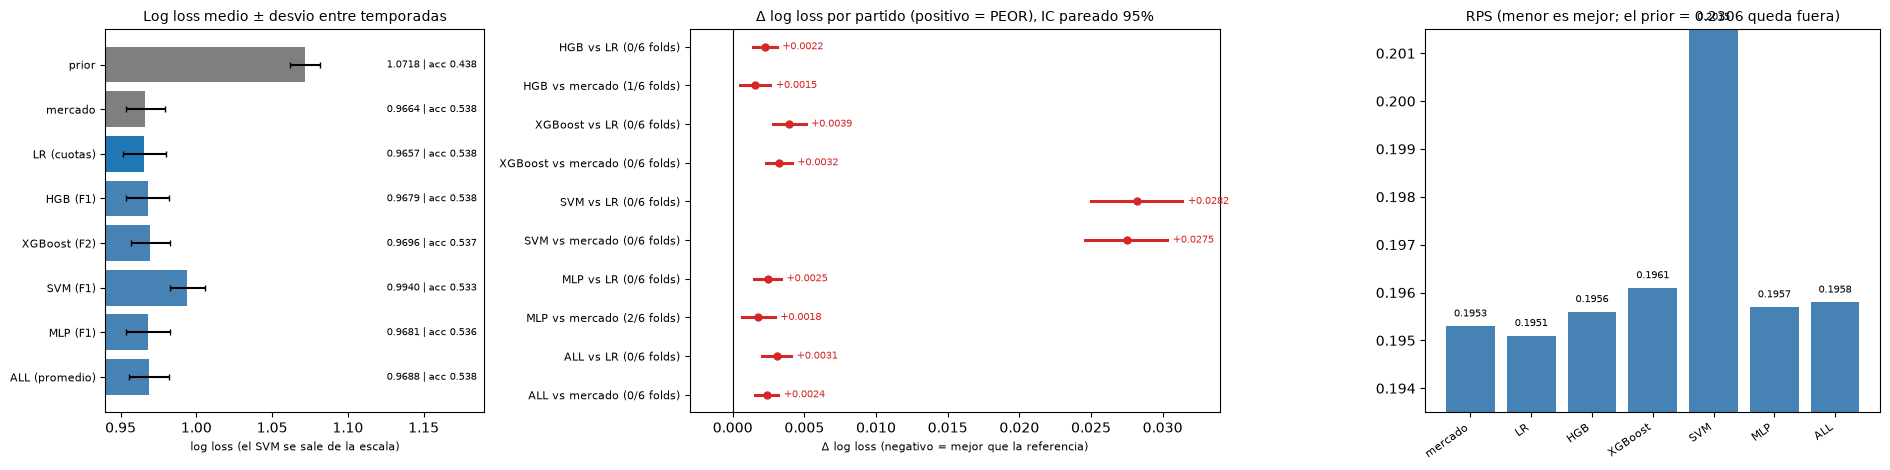

In [9]:
def rps(P, yy):
    O = np.eye(3)[yy]
    return float(np.mean(0.5 * (((np.cumsum(P, axis=1) - np.cumsum(O, axis=1))[:, :2]) ** 2).sum(axis=1)))

hp_h = HP['HGB_clas']
hgb_t = lambda: HistGradientBoostingClassifier(learning_rate=hp_h['learning_rate'], max_depth=int(hp_h['max_depth']), min_samples_leaf=int(hp_h['min_samples_leaf']),
                                                max_iter=int(hp_h['max_iter']), l2_regularization=1.0, random_state=42)
lr_t = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=HP['LR_clas']['C'], max_iter=5000))
hs, hx, hm = HP6['SVM'], HP6['XGB'], HP6['MLP']
hidden = eval(hm['hidden'])

nombres = ['prior', 'mercado', 'LR (cuotas)', 'HGB (F1)', 'XGBoost (F2)', 'SVM (F1)', 'MLP (F1)', 'ALL (promedio)']
OOF, filas = {n: [] for n in nombres}, []
idx_all, y_all, fold_all = [], [], []
for s in FOLDS:
    tr, va = seas < s, seas == s
    ix_cap = cap(tr)
    pri = np.bincount(y[tr], minlength=3) / tr.sum()
    P = {'prior': np.tile(pri, (va.sum(), 1)),
         'mercado': odds.loc[va, ['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy(),
         'LR (cuotas)': lr_t().fit(X1.loc[tr, MKT], y[tr]).predict_proba(X1.loc[va, MKT]),
         'HGB (F1)': hgb_t().fit(X1.loc[tr, F1], y[tr]).predict_proba(X1.loc[va, F1]),
         'XGBoost (F2)': xgb_fab(hx['learning_rate'], int(hx['max_depth']), int(hx['n_estimators']), hx['min_child_weight']).fit(X2[tr], y[tr]).predict_proba(X2[va]),
         'SVM (F1)': svm_fab(hs['C'], hs['gamma']).fit(XF1[ix_cap], y[ix_cap]).predict_proba(XF1[va]),
         'MLP (F1)': prob_mlp(hidden, hm['alpha'], XF1[tr], y[tr], XF1[va])}
    P['ALL (promedio)'] = np.mean([P[k] for k in ('LR (cuotas)', 'HGB (F1)', 'XGBoost (F2)', 'SVM (F1)', 'MLP (F1)')], axis=0)
    for n in nombres:
        OOF[n].append(P[n])
        filas.append(dict(fold=int(s), modelo=n, ll=log_loss(y[va], P[n], labels=[0, 1, 2]), rps=rps(P[n], y[va]), acc=accuracy_score(y[va], P[n].argmax(1))))
    idx_all.append(np.where(va)[0]); y_all.append(y[va]); fold_all.append(np.full(va.sum(), int(s)))
OOF = {n: np.vstack(v) for n, v in OOF.items()}
yv, fv = np.concatenate(y_all), np.concatenate(fold_all)
rf = pd.DataFrame(filas)
tab = rf.groupby('modelo', sort=False).agg(ll=('ll', 'mean'), ll_std=('ll', 'std'), rps=('rps', 'mean'), acc=('acc', 'mean')).round(4)

# diferencia por partido frente a la LR sobre cuotas y frente al mercado (bootstrap pareado)
pl = lambda n: -np.log(np.clip(OOF[n][np.arange(len(yv)), yv], 1e-9, 1))
rng = np.random.default_rng(5)
def dif(a, b):
    d = pl(a) - pl(b)
    bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(1000)]
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), float((d.mean() < 0))
filas2 = []
for n in nombres[3:]:
    for ref in ('LR (cuotas)', 'mercado'):
        m_, lo, hi, _ = dif(n, ref)
        fo = rf[rf.modelo == n].set_index('fold').ll - rf[rf.modelo == ref].set_index('fold').ll
        filas2.append(dict(modelo=n, vs=ref, delta=m_, lo=lo, hi=hi, significativo=bool(hi < 0 or lo > 0), folds_mejor=f'{int((fo < 0).sum())}/{len(fo)}'))
t_cmp = pd.DataFrame(filas2)
fig, axs = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={'width_ratios': [1, 1.4, 1.2]})
axs[0].barh(range(len(tab))[::-1], tab.ll, xerr=tab.ll_std, color=['tab:gray' if n_ in ('prior', 'mercado') else 'tab:blue' if n_.startswith('LR') else 'steelblue' for n_ in tab.index], capsize=2); axs[0].set_xlim(0.94, 1.19)
axs[0].set_yticks(range(len(tab))[::-1]); axs[0].set_yticklabels(tab.index, fontsize=8)
for yi, (v_, a_) in zip(range(len(tab))[::-1], zip(tab.ll, tab.acc)): axs[0].text(1.185, yi, f'{v_:.4f} | acc {a_:.3f}', va='center', ha='right', fontsize=7)
axs[0].set_title('Log loss medio ± desvio entre temporadas', fontsize=10); axs[0].set_xlabel('log loss (el SVM se sale de la escala)', fontsize=8)
et = [f"{r.modelo.split(' (')[0]} vs {'LR' if r.vs.startswith('LR') else 'mercado'} ({r.folds_mejor} folds)" for r in t_cmp.itertuples()]
forest(axs[1], et, t_cmp.delta.to_numpy(), t_cmp.lo.to_numpy(), t_cmp.hi.to_numpy(), 'Δ log loss por partido (positivo = PEOR), IC pareado 95%')
axs[1].set_xlim(-0.003, 0.034)
axs[2].bar(range(len(tab) - 1), tab.loc[[n_ for n_ in tab.index if n_ != 'prior'], 'rps'], color='steelblue'); axs[2].set_ylim(0.1935, 0.2015)
axs[2].set_xticks(range(len(tab) - 1)); axs[2].set_xticklabels([n_.split(' (')[0] for n_ in tab.index if n_ != 'prior'], rotation=35, ha='right', fontsize=8)
for x_, v_ in enumerate(tab.loc[[n_ for n_ in tab.index if n_ != 'prior'], 'rps']): axs[2].text(x_, v_ + 0.0002, f'{v_:.4f}', ha='center', fontsize=7)
axs[2].set_title('RPS (menor es mejor; el prior = 0.2306 queda fuera)', fontsize=10)
plt.tight_layout(); plt.show()
pd.concat([pd.DataFrame({'idx': np.concatenate(idx_all), 'fold': fv, 'y': yv})] + [pd.DataFrame(OOF[n], columns=[f'{n}|{l}' for l in 'HDA']) for n in nombres], axis=1).to_csv(DATA + 'modelos_oof.csv', index=False)

**Hallazgo.** Media de los 6 folds temporales:

| Modelo | Log loss | Desvío | RPS | Accuracy |
|---|---|---|---|---|
| Prior | 1.0718 | 0.0098 | 0.2309 | 0.438 |
| Mercado crudo | 0.9664 | 0.0128 | 0.1953 | 0.538 |
| **LR (cuotas)** | **0.9657** | 0.0141 | **0.1951** | 0.538 |
| HGB (F1) | 0.9679 | 0.0142 | 0.1956 | 0.538 |
| MLP (F1) | 0.9681 | 0.0143 | 0.1957 | 0.536 |
| ALL (promedio) | 0.9688 | 0.0132 | 0.1958 | 0.538 |
| XGBoost (F2) | 0.9696 | 0.0127 | 0.1961 | 0.537 |
| SVM (F1) | 0.9940 | 0.0116 | 0.2015 | 0.533 |

*Diferencia de log loss por partido (positivo = el modelo es **peor**), con IC pareado al 95%:*

| Modelo | vs LR (cuotas) | vs mercado crudo | Folds en que supera a la LR |
|---|---|---|---|
| HGB | +0.0022 [+0.0014, +0.0031] | +0.0015 [+0.0005, +0.0026] | 0/6 |
| MLP | +0.0025 [+0.0015, +0.0034] | +0.0018 [+0.0007, +0.0029] | 0/6 |
| ALL | +0.0031 [+0.0020, +0.0041] | +0.0024 [+0.0016, +0.0032] | 0/6 |
| XGBoost | +0.0039 [+0.0028, +0.0051] | +0.0032 [+0.0023, +0.0041] | 0/6 |
| SVM | +0.0282 [+0.0250, +0.0314] | +0.0275 [+0.0246, +0.0303] | 0/6 |

1. **Ningún modelo supera a la LR sobre cuotas ni al mercado crudo.** Todos los intervalos están por encima de 0: son **peores**, no empatados.
2. **A mayor flexibilidad, peor:** LR (3 variables) < HGB ≈ MLP < ALL < XGBoost < SVM. La relación entre las cuotas y el resultado es casi lineal y el resto de features es ruido para estos modelos.
3. **El SVM es el peor por mucho** (+0.028), incluso con `C` y `gamma` elegidos: con 9,000 filas y el escalamiento de Platt interno, el SVM RBF produce probabilidades poco finas; se mantiene como evidencia de que no es el modelo adecuado para este problema.
4. **El ensemble no ayuda:** promediar cinco modelos con la LR no mejora a la LR; lo que añade es el ruido de los demás.

**Decisión.** El modelo recomendado es la **regresión logística sobre las cuotas**. Los modelos más complejos quedan como comparación del enunciado, con su resultado negativo documentado.

## Paso 8 — Calibración de los modelos finales

**Qué vamos a hacer.** Un modelo puede tener buen log loss y estar mal calibrado (o al revés). Se mide:

1. **ECE** (error de calibración esperado, 10 tramos) para cada resultado, y su promedio.
2. **Curva de fiabilidad** del resultado local para el mercado, la LR sobre cuotas y el ensemble.

**Por qué.** La calibración es lo que permite comparar con las cuotas para detectar valor; un modelo sobreconfiado pierde dinero aunque "acierte" bastante (lo que vimos con el modelo sin cuotas en `06_mercado.ipynb`).

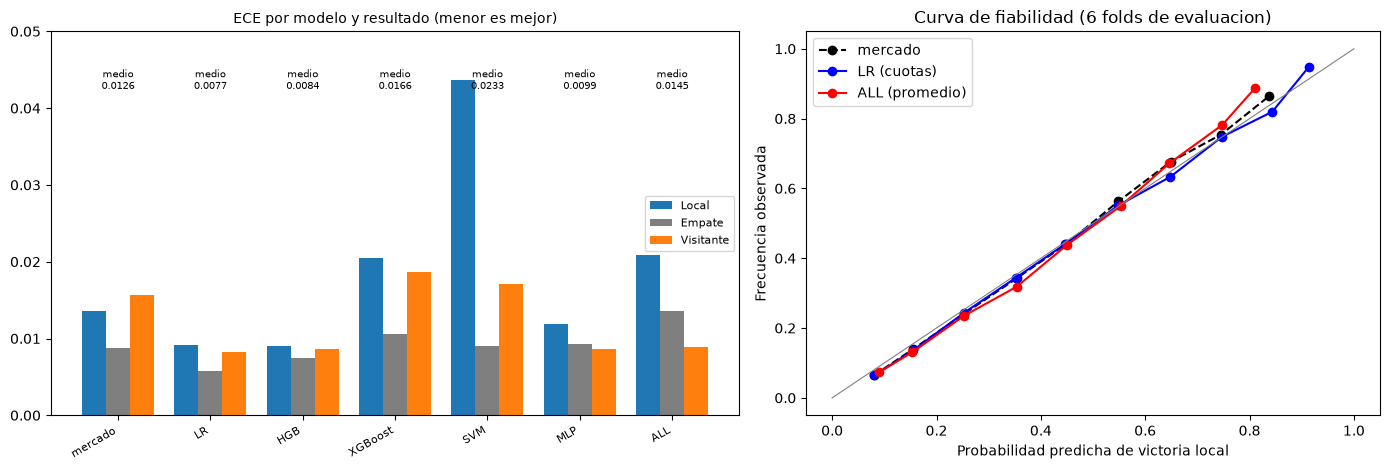

In [10]:
import matplotlib.pyplot as plt

def ece(p, o, nb=10):
    b_ = np.minimum((p * nb).astype(int), nb - 1)
    return float(sum((b_ == k).mean() * abs(o[b_ == k].mean() - p[b_ == k].mean()) for k in np.unique(b_)))

filas = []
for n in nombres[1:]:
    e = [ece(OOF[n][:, j], (yv == j)) for j in range(3)]
    filas.append(dict(modelo=n, ECE_H=e[0], ECE_D=e[1], ECE_A=e[2], ECE_medio=float(np.mean(e))))
ece_df = pd.DataFrame(filas).set_index('modelo')
fig, axs_ = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.2, 1]}); ax = axs_[1]
xs_ = np.arange(len(ece_df)); w_ = 0.26
for k_, (col_, lab_, c_) in enumerate((('ECE_H', 'Local', 'tab:blue'), ('ECE_D', 'Empate', 'tab:gray'), ('ECE_A', 'Visitante', 'tab:orange'))): axs_[0].bar(xs_ + (k_ - 1) * w_, ece_df[col_], w_, label=lab_, color=c_)
axs_[0].set_xticks(xs_); axs_[0].set_xticklabels([n_.split(' (')[0] for n_ in ece_df.index], rotation=30, ha='right', fontsize=8); axs_[0].legend(fontsize=8)
for x_, v_ in zip(xs_, ece_df.ECE_medio): axs_[0].text(x_, 0.0425, f'medio\n{v_:.4f}', ha='center', fontsize=7)
axs_[0].set_ylim(0, 0.05); axs_[0].set_title('ECE por modelo y resultado (menor es mejor)', fontsize=10)
edges = np.linspace(0, 1, 11)
for n, st in (('mercado', 'k--'), ('LR (cuotas)', 'b-'), ('ALL (promedio)', 'r-')):
    p = OOF[n][:, 0]; o = (yv == 0)
    b_ = np.minimum((p * 10).astype(int), 9)
    xs = [p[b_ == k].mean() for k in range(10) if (b_ == k).sum() > 50]
    ys = [o[b_ == k].mean() for k in range(10) if (b_ == k).sum() > 50]
    ax.plot(xs, ys, st, marker='o', label=n)
ax.plot([0, 1], [0, 1], color='gray', lw=0.8)
ax.set_xlabel('Probabilidad predicha de victoria local'); ax.set_ylabel('Frecuencia observada'); ax.set_title('Curva de fiabilidad (6 folds de evaluacion)'); ax.legend(); plt.tight_layout(); plt.show()

**Hallazgo.**

| Modelo | ECE (H) | ECE (D) | ECE (A) | ECE medio |
|---|---|---|---|---|
| Mercado crudo | 0.0135 | 0.0087 | 0.0156 | 0.0126 |
| **LR (cuotas)** | **0.0092** | **0.0058** | **0.0082** | **0.0077** |
| HGB (F1) | 0.0091 | 0.0075 | 0.0086 | 0.0084 |
| MLP (F1) | 0.0119 | 0.0093 | 0.0087 | 0.0099 |
| ALL (promedio) | 0.0209 | 0.0135 | 0.0089 | 0.0145 |
| XGBoost (F2) | 0.0205 | 0.0105 | 0.0187 | 0.0166 |
| SVM (F1) | 0.0436 | 0.0091 | 0.0172 | 0.0233 |

- **La LR sobre cuotas reduce el error de calibración del mercado en casi un 40%** (0.0126 → 0.0077): es la recalibración del sesgo favorito–longshot vista en `06_mercado.ipynb`.
- **XGBoost y SVM están peor calibrados que el mercado** (0.017 y 0.023), y arrastran al ensemble (0.0145).
- Esto explica en parte el orden de log loss del Paso 7.

**Decisión.** Reportar la LR sobre cuotas como modelo final: mejor log loss, mejor RPS y mejor calibración, con tres variables.

## Paso 9 — Selección de características: Mutual Information vs. PCA

**Qué vamos a hacer.** Responder la pregunta de investigación 3: *¿qué técnica de reducción de dimensionalidad preserva mejor la señal predictiva: **MI** (seleccionar variables) o **PCA** (proyectar), como en Tammouch et al.?*

**Diseño.**

| Elemento | Detalle |
|---|---|
| **Dos conjuntos de variables** | **Con cuotas**: F1 + habilidades (46 variables, todas sin NaN). **Sin cuotas**: plantilla + forma + habilidades (43 variables). El segundo es el que se parece al escenario del paper: sin una variable dominante, donde la reducción puede importar |
| **Métodos** | Todas las variables; MI top-`k` con `k ∈ {5, 10, 20}`; PCA con `k ∈ {5, 10, 20}` componentes; PCA con 95% y 99% de varianza |
| **Sin fuga** | MI y PCA (con su estandarización) se calculan **solo con el entrenamiento de cada fold** |
| **Modelos** | LR (`C` elegido), HGB y MLP (hiperparámetros elegidos en los Pasos 6a y 6) |
| **Elección de `k`** | Con la **ventana de ajuste** (2016/17–2017/18): para cada técnica y modelo se elige la `k` con menor log loss; se reporta en los 6 folds de evaluación |
| **Referencia** | *Todas las variables* y, para el conjunto con cuotas, el mercado |

**Por qué.** Tammouch et al. reportan que MI > PCA con 156 variables y 4 mil partidos, y que PCA descarta variables de baja varianza con valor predictivo. Aquí hay 30 mil partidos de train/val y 43–46 variables: es una réplica en un régimen distinto.

componentes para 95% / 99% de varianza (ultimo fold):
  conjunto  metodo  componentes
Con cuotas PCA-95%           27
Con cuotas PCA-99%           40
Sin cuotas PCA-95%           25
Sin cuotas PCA-99%           37

Top MI (ultimo fold) - Con cuotas: {'MKT_logit': 0.097, 'DIF_sq_top11': 0.086, 'SK_vision': 0.069, 'SK_reactions': 0.069, 'SK_ball_control': 0.069, 'SK_positioning': 0.067, 'SK_long_passing': 0.066, 'SK_sliding_tackle': 0.064}

Top MI (ultimo fold) - Sin cuotas: {'DIF_sq_top11': 0.078, 'SK_ball_control': 0.073, 'SK_reactions': 0.068, 'SK_dribbling': 0.068, 'SK_interceptions': 0.065, 'SK_short_passing': 0.064, 'SK_positioning': 0.063, 'SK_standing_tackle': 0.063}


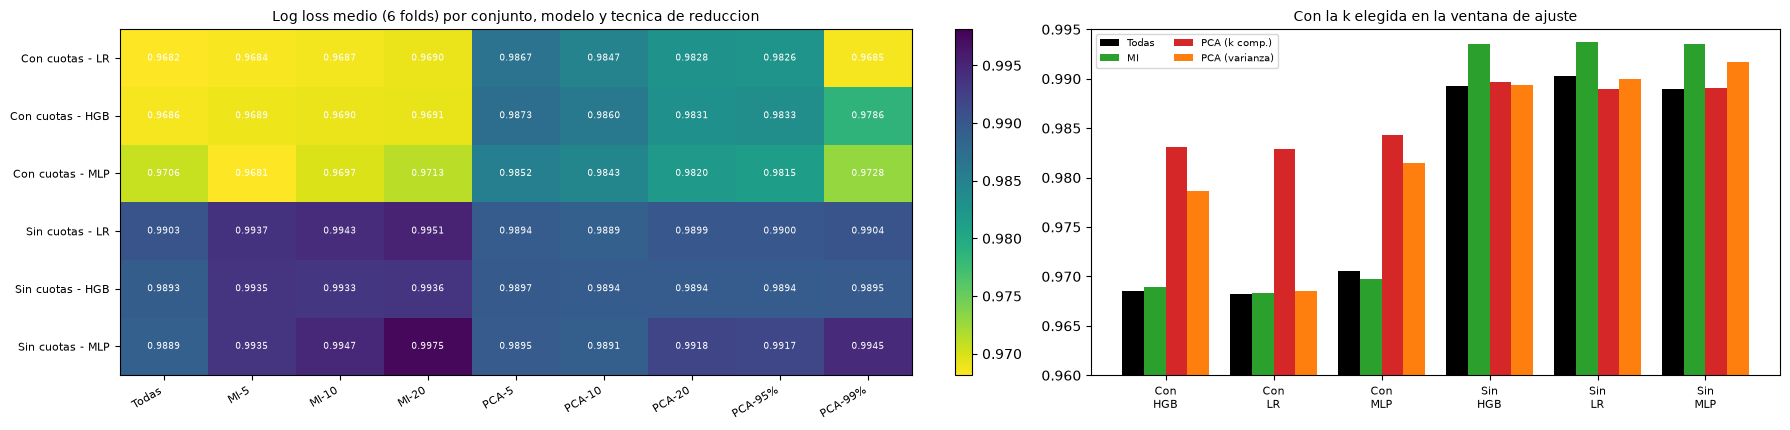

Top MI (ultimo fold): {'Con cuotas': ['MKT_logit', 'DIF_sq_top11', 'SK_vision', 'SK_reactions', 'SK_ball_control'], 'Sin cuotas': ['DIF_sq_top11', 'SK_ball_control', 'SK_reactions', 'SK_dribbling', 'SK_interceptions']}


In [11]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA

CON = F1 + SK
SIN = SQ + FORMA + SK
CONJ = {'Con cuotas': CON, 'Sin cuotas': SIN}
METODOS = ['Todas'] + [f'MI-{k}' for k in (5, 10, 20)] + [f'PCA-{k}' for k in (5, 10, 20)] + ['PCA-95%', 'PCA-99%']
FAM = {'MI': ['MI-5', 'MI-10', 'MI-20'], 'PCA (k comp.)': ['PCA-5', 'PCA-10', 'PCA-20'], 'PCA (varianza)': ['PCA-95%', 'PCA-99%']}
FOLDS_ALL = list(TUNE) + [int(s) for s in FOLDS]

def mod_lr(): return lr_t()
def mod_hgb(): return hgb_t()
def mod_mlp(): return mlp_fab(hidden, hm['alpha'], 0)
MODS = {'LR': mod_lr, 'HGB': mod_hgb, 'MLP': mod_mlp}

def transformar(metodo, Xtr, Xva, mi):
    if metodo == 'Todas':
        return Xtr, Xva
    if metodo.startswith('MI-'):
        k = int(metodo.split('-')[1]); ix = np.argsort(mi)[::-1][:k]
        return Xtr[:, ix], Xva[:, ix]
    sc = StandardScaler().fit(Xtr)
    n = int(metodo.split('-')[1]) if 'comp' not in metodo and '%' not in metodo else float(metodo.split('-')[1].strip('%')) / 100
    p = PCA(n_components=n, svd_solver='full', random_state=42).fit(sc.transform(Xtr))
    return p.transform(sc.transform(Xtr)), p.transform(sc.transform(Xva))

filas, info_pca, mi_top = [], [], {}
for nom_c, cols in CONJ.items():
    Xc = Xall[cols].to_numpy(float)
    for s in FOLDS_ALL:
        tr, va = seas < s, seas == s
        mi = mutual_info_classif(Xc[tr], y[tr], random_state=42, n_neighbors=3, n_jobs=-1)
        if s == FOLDS_ALL[-1]:
            mi_top[nom_c] = pd.Series(mi, index=cols).sort_values(ascending=False).head(8)
        for metodo in METODOS:
            Xt, Xv = transformar(metodo, Xc[tr], Xc[va], mi)
            if metodo.startswith('PCA-') and s == FOLDS_ALL[-1]:
                info_pca.append(dict(conjunto=nom_c, metodo=metodo, componentes=Xt.shape[1]))
            for nom_m, fab in MODS.items():
                p_ = fab().fit(Xt, y[tr]).predict_proba(Xv)
                filas.append(dict(conjunto=nom_c, metodo=metodo, modelo=nom_m, fold=s, ll=log_loss(y[va], p_, labels=[0, 1, 2])))
sel = pd.DataFrame(filas)
sel['ventana'] = sel.fold.isin(TUNE)
sel.to_csv(DATA + 'seleccion_caracteristicas.csv', index=False)
print('componentes para 95% / 99% de varianza (ultimo fold):'); print(pd.DataFrame(info_pca).query("metodo in ['PCA-95%', 'PCA-99%']").to_string(index=False))
for k, v in mi_top.items():
    print(f'\nTop MI (ultimo fold) - {k}:', v.round(3).to_dict())

# elegir k por tecnica y modelo con la ventana de ajuste; reportar en los folds de evaluacion
ev = sel[~sel.ventana]; vt = sel[sel.ventana]
resumen = []
for nom_c in CONJ:
    for nom_m in MODS:
        base = ev[(ev.conjunto == nom_c) & (ev.modelo == nom_m) & (ev.metodo == 'Todas')].ll
        resumen.append(dict(conjunto=nom_c, modelo=nom_m, tecnica='Todas', elegido='Todas', ll=base.mean(), ll_std=base.std()))
        for fam, lst in FAM.items():
            v = vt[(vt.conjunto == nom_c) & (vt.modelo == nom_m) & (vt.metodo.isin(lst))].groupby('metodo').ll.mean()
            ele = v.idxmin()
            e = ev[(ev.conjunto == nom_c) & (ev.modelo == nom_m) & (ev.metodo == ele)].ll
            resumen.append(dict(conjunto=nom_c, modelo=nom_m, tecnica=fam, elegido=ele, ll=e.mean(), ll_std=e.std()))
resumen = pd.DataFrame(resumen)
malla = ev.groupby(['conjunto', 'modelo', 'metodo'], sort=False).ll.mean().unstack('metodo')[METODOS]
fig, axs = plt.subplots(1, 2, figsize=(18, 4.4), gridspec_kw={'width_ratios': [1.25, 1]})
im = axs[0].imshow(malla.to_numpy(), aspect='auto', cmap='viridis_r', vmin=malla.to_numpy().min(), vmax=malla.to_numpy().min() + 0.03)
axs[0].set_xticks(range(len(METODOS))); axs[0].set_xticklabels(METODOS, rotation=30, ha='right', fontsize=8); axs[0].set_yticks(range(len(malla))); axs[0].set_yticklabels([f'{a_} - {b_}' for a_, b_ in malla.index], fontsize=8)
for i_ in range(malla.shape[0]):
    for j_ in range(malla.shape[1]): axs[0].text(j_, i_, f'{malla.iloc[i_, j_]:.4f}', ha='center', va='center', fontsize=6.5, color='white')
fig.colorbar(im, ax=axs[0], fraction=0.03); axs[0].set_title('Log loss medio (6 folds) por conjunto, modelo y tecnica de reduccion', fontsize=10)
piv = resumen.pivot_table(index=['conjunto', 'modelo'], columns='tecnica', values='ll')[['Todas', 'MI', 'PCA (k comp.)', 'PCA (varianza)']]
xs = np.arange(len(piv)); w = 0.2
for k, (tec, col_) in enumerate(zip(piv.columns, ['black', 'tab:green', 'tab:red', 'tab:orange'])): axs[1].bar(xs + (k - 1.5) * w, piv[tec], w, label=tec, color=col_)
axs[1].set_ylim(0.96, 0.995); axs[1].set_xticks(xs); axs[1].set_xticklabels([f'{a_.split()[0]}\n{b_}' for a_, b_ in piv.index], fontsize=8); axs[1].legend(fontsize=7, ncol=2); axs[1].set_title('Con la k elegida en la ventana de ajuste', fontsize=10)
plt.tight_layout(); plt.show()
print('Top MI (ultimo fold):', {k: list(v.index[:5]) for k, v in mi_top.items()})

**Hallazgo.** Log loss medio en los 6 folds de evaluación (`k` elegida en la ventana de ajuste; prior 1.0718, mercado 0.9664):

| Conjunto | Modelo | Todas | MI (`k` elegida) | PCA (`k` comp.) | PCA (varianza) |
|---|---|---|---|---|---|
| **Con cuotas** (46 vars) | LR | **0.9682** | 0.9684 (MI-5) | 0.9828 (PCA-20) | 0.9685 (99%) |
| | HGB | **0.9686** | 0.9689 (MI-5) | 0.9831 (PCA-20) | 0.9786 (99%) |
| | MLP | 0.9706 | **0.9697** (MI-10) | 0.9843 (PCA-10) | 0.9815 (95%) |
| **Sin cuotas** (43 vars) | LR | 0.9903 | 0.9937 (MI-5) | **0.9889** (PCA-10) | 0.9900 (95%) |
| | HGB | **0.9893** | 0.9935 (MI-5) | 0.9897 (PCA-5) | 0.9894 (95%) |
| | MLP | **0.9889** | 0.9935 (MI-5) | 0.9891 (PCA-10) | 0.9917 (95%) |

El PCA con 95% / 99% de varianza necesita 25–27 / 37–40 componentes: la variabilidad está repartida entre muchas variables correlacionadas.

**Hallazgo clave.** El resultado **depende de si hay una variable dominante**:

- **Con cuotas, MI gana de forma clara** (Δ = −0.014 en 6/6 folds, ver abajo). Es lógico: MI conserva `MKT_logit`, la variable que concentra la señal; el PCA la mezcla con 45 variables ruidosas y necesita ≥ 20 componentes (o el 99% de varianza) para recuperarla. Aun así **ninguna técnica supera a usar todas las variables** (salvo un empate técnico del MLP con MI-10, −0.0009): MI-5 empata (0.9684 vs 0.9682) y es equivalente a "usar solo el mercado".
- **Sin cuotas, PCA queda mejor que MI** (Δ = +0.004 a +0.005; MI mejor en solo 0–2 de 6 folds) y **empata con usar todas las variables** (PCA-10 mejora a la LR en 0.0014; con HGB y MLP la diferencia es ≤ 0.0004). El MI univariado elige las 5–20 variables con más dependencia individual, que son habilidades muy correlacionadas entre sí (`ball_control`, `reactions`, `dribbling`, `interceptions`, `short_passing`, `positioning`, `standing_tackle`), y descarta la forma y otras variables **complementarias** con poca MI individual. El PCA, en cambio, resume la varianza compartida y conserva algo de lo demás.

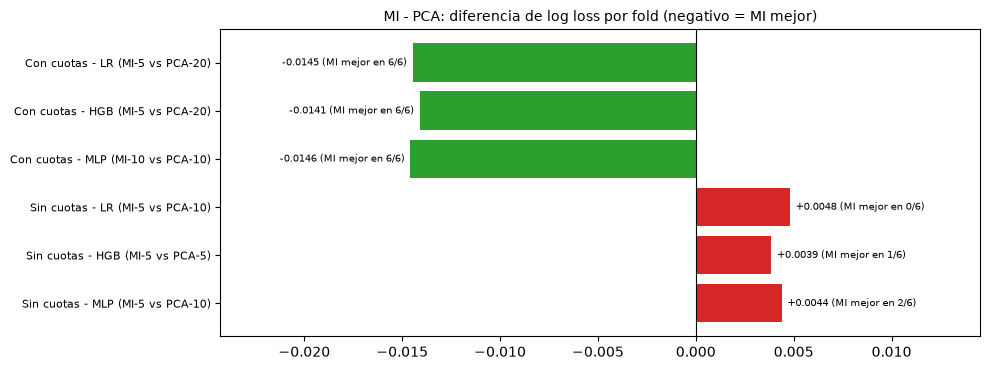


referencias (6 folds): prior 1.0718 | mercado 0.9664


In [12]:
# comparacion pareada MI vs PCA con la k elegida en la ventana (por fold)
filas = []
for nom_c in CONJ:
    for nom_m in MODS:
        r_mi = resumen[(resumen.conjunto == nom_c) & (resumen.modelo == nom_m) & (resumen.tecnica == 'MI')].elegido.iloc[0]
        r_pc = resumen[(resumen.conjunto == nom_c) & (resumen.modelo == nom_m) & (resumen.tecnica == 'PCA (k comp.)')].elegido.iloc[0]
        a = ev[(ev.conjunto == nom_c) & (ev.modelo == nom_m) & (ev.metodo == r_mi)].set_index('fold').ll
        b = ev[(ev.conjunto == nom_c) & (ev.modelo == nom_m) & (ev.metodo == r_pc)].set_index('fold').ll
        d = a - b
        filas.append(dict(conjunto=nom_c, modelo=nom_m, MI=r_mi, PCA=r_pc, delta_medio=d.mean(), folds_MI_mejor=f'{int((d < 0).sum())}/{len(d)}'))
dm = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(range(len(dm))[::-1], dm.delta_medio, color=['tab:green' if v < 0 else 'tab:red' for v in dm.delta_medio]); ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(range(len(dm))[::-1]); ax.set_yticklabels([f'{r.conjunto} - {r.modelo} ({r.MI} vs {r.PCA})' for r in dm.itertuples()], fontsize=8)
for yi, r in zip(range(len(dm))[::-1], dm.itertuples()): ax.annotate(f'{r.delta_medio:+.4f} (MI mejor en {r.folds_MI_mejor})', (r.delta_medio, yi), xytext=(4 if r.delta_medio >= 0 else -4, 0), textcoords='offset points', ha='left' if r.delta_medio >= 0 else 'right', va='center', fontsize=7)
ax.set_title('MI - PCA: diferencia de log loss por fold (negativo = MI mejor)', fontsize=10); ax.margins(x=0.5); plt.tight_layout(); plt.show()
# referencia: que tan lejos queda cada tecnica del prior y del mercado
pri = rf[rf.modelo == 'prior'].ll.mean(); mer = rf[rf.modelo == 'mercado'].ll.mean()
print(f'\nreferencias (6 folds): prior {pri:.4f} | mercado {mer:.4f}')

**Hallazgo.** Comparación pareada de MI vs PCA (`k` comp.), diferencia de log loss por fold (negativo = MI mejor):

| Conjunto | Modelo | MI | PCA | Δ medio | Folds en que MI es mejor |
|---|---|---|---|---|---|
| Con cuotas | LR | MI-5 | PCA-20 | **−0.0145** | 6/6 |
| Con cuotas | HGB | MI-5 | PCA-20 | **−0.0141** | 6/6 |
| Con cuotas | MLP | MI-10 | PCA-10 | **−0.0146** | 6/6 |
| Sin cuotas | LR | MI-5 | PCA-10 | +0.0048 | 0/6 |
| Sin cuotas | HGB | MI-5 | PCA-5 | +0.0039 | 1/6 |
| Sin cuotas | MLP | MI-5 | PCA-10 | +0.0044 | 2/6 |

**Respuesta a la pregunta de investigación 3.**

1. **MI > PCA solo cuando hay una variable dominante** (las cuotas), que es el escenario de Tammouch et al. Ahí se **replica** su hallazgo y por la misma razón que ellos dan: PCA descarta o diluye variables con información.
2. **Sin variable dominante, el resultado se invierte** (PCA ≥ MI por 0.004–0.005): no se replica.
3. **En ambos casos, reducir no aporta casi nada:** con 30 mil partidos de train/val y 43–46 variables **no hay maldición de la dimensionalidad** y los modelos regularizados ya manejan la redundancia. La diferencia entre técnicas (0.004–0.015) es mucho menor que la ganancia sobre el prior (0.08–0.10), y la mejor reducción (PCA-10 sin cuotas, LR) gana solo 0.0014 a usar todas las variables.

**Decisión.** Mantener todas las variables en los modelos finales (o solo las cuotas, que es lo que se recomienda). La selección por MI queda como ranking descriptivo.

## Paso 10 — Preguntas de investigación e hipótesis

**Qué vamos a hacer.** Cerrar explícitamente las preguntas y las hipótesis planteadas en el informe con los mismos folds temporales y los mismos modelos:

| # | Pregunta / hipótesis | Prueba |
|---|---|---|
| 1 | ¿El desempeño es estable entre temporadas o se degrada (*concept drift*)? | Log loss por fold, tendencia de `modelo − mercado` y entrenar con todo el pasado vs. solo las últimas 3 temporadas |
| 2 | ¿La plantilla mejora la predicción respecto a solo estadísticas históricas de partido? | LR y HGB con forma (G), plantilla (S) y ambas, sin y con cuotas; diferencia por partido con IC pareado |
| (ii) | ¿La plantilla aporta más **al inicio de la temporada**, cuando la forma es escasa? | Mejora por partido de añadir S, agrupada por semana de la temporada |

(La pregunta 4 —*value bets* con un ensemble—, la hipótesis (i) y la hipótesis (iii) —calibración frente a dinero— se responden en `06_mercado.ipynb` (Pasos 7 y 8) y en los Pasos 2 y 7 de este cuaderno.)

  tendencia de mercado         : pendiente por temporada = -0.00300 (p = 0.385) | Spearman = -0.37 (p = 0.468)
  tendencia de LR (cuotas)     : pendiente por temporada = -0.00349 (p = 0.356) | Spearman = -0.37 (p = 0.468)
  tendencia de LR - mercado    : pendiente por temporada = -0.00049 (p = 0.167) | Spearman = -0.71 (p = 0.111)
  tendencia de mercado - prior : pendiente por temporada = -0.00356 (p = 0.201) | Spearman = -0.43 (p = 0.397)


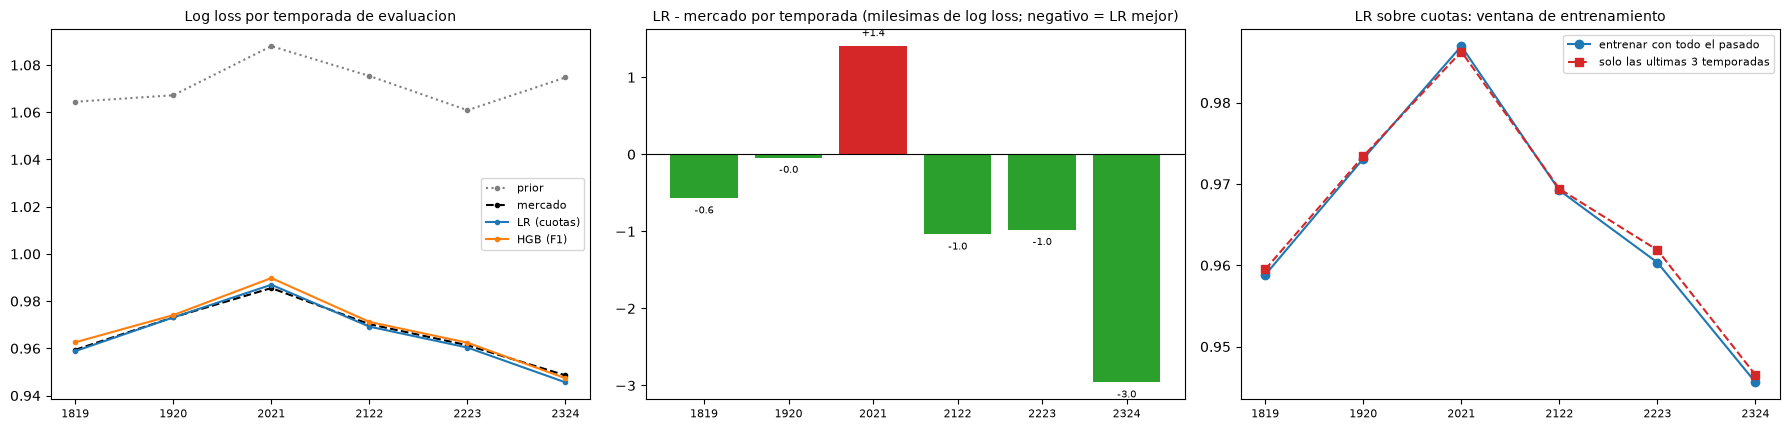

  diferencia media (ultimas 3 - todo): 0.00049 | folds donde las ultimas 3 son mejores: 1 / 6


In [13]:
# --- 1) estabilidad temporal
tab_f = rf.pivot(index='fold', columns='modelo', values='ll')[['prior', 'mercado', 'LR (cuotas)', 'HGB (F1)']]
tab_f['LR - mercado'] = tab_f['LR (cuotas)'] - tab_f['mercado']
tab_f['mercado - prior'] = tab_f['mercado'] - tab_f['prior']
from scipy.stats import spearmanr, linregress
orden_f = np.arange(len(tab_f))
for col in ('mercado', 'LR (cuotas)', 'LR - mercado', 'mercado - prior'):
    lr_ = linregress(orden_f, tab_f[col].to_numpy())
    rho, pr = spearmanr(orden_f, tab_f[col].to_numpy())
    print(f'  tendencia de {col:<16}: pendiente por temporada = {lr_.slope:+.5f} (p = {lr_.pvalue:.3f}) | Spearman = {rho:+.2f} (p = {pr:.3f})')

# entrenar con todo el pasado vs. solo las ultimas 3 temporadas (LR sobre cuotas)
filas_w = []
for s in FOLDS:
    va = seas == s
    tr_all = seas < s
    tr_w = (seas < s) & (seas >= temporadas[max(temporadas.index(s) - 3, 0)])
    pa = lr_t().fit(X1.loc[tr_all, MKT], y[tr_all]).predict_proba(X1.loc[va, MKT])
    pw = lr_t().fit(X1.loc[tr_w, MKT], y[tr_w]).predict_proba(X1.loc[va, MKT])
    filas_w.append(dict(fold=int(s), todo_el_pasado=log_loss(y[va], pa), ultimas_3=log_loss(y[va], pw)))
w = pd.DataFrame(filas_w); w['dif'] = w.ultimas_3 - w.todo_el_pasado
fig, axs = plt.subplots(1, 3, figsize=(18, 4.4))
for n_, col_, ls_ in (('prior', 'tab:gray', ':'), ('mercado', 'k', '--'), ('LR (cuotas)', 'tab:blue', '-'), ('HGB (F1)', 'tab:orange', '-')): axs[0].plot(range(len(tab_f)), tab_f[n_], marker='o', ms=3, color=col_, ls=ls_, label=n_)
axs[0].set_xticks(range(len(tab_f))); axs[0].set_xticklabels(tab_f.index, fontsize=8); axs[0].legend(fontsize=8); axs[0].set_title('Log loss por temporada de evaluacion', fontsize=10)
dd_ = tab_f['LR - mercado'] * 1000; axs[1].bar(range(len(dd_)), dd_, color=['tab:green' if v < 0 else 'tab:red' for v in dd_]); axs[1].axhline(0, color='k', lw=0.8); axs[1].set_xticks(range(len(dd_))); axs[1].set_xticklabels(tab_f.index, fontsize=8)
for x_, v in enumerate(dd_): axs[1].text(x_, v + (0.1 if v >= 0 else -0.1), f'{v:+.1f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=7)
axs[1].set_title('LR - mercado por temporada (milesimas de log loss; negativo = LR mejor)', fontsize=10)
axs[2].plot(range(len(w)), w.todo_el_pasado, marker='o', color='tab:blue', label='entrenar con todo el pasado'); axs[2].plot(range(len(w)), w.ultimas_3, marker='s', color='tab:red', ls='--', label='solo las ultimas 3 temporadas')
axs[2].set_xticks(range(len(w))); axs[2].set_xticklabels(w.fold, fontsize=8); axs[2].legend(fontsize=8); axs[2].set_title('LR sobre cuotas: ventana de entrenamiento', fontsize=10)
plt.tight_layout(); plt.show()
print('  diferencia media (ultimas 3 - todo):', round(float(w.dif.mean()), 5), '| folds donde las ultimas 3 son mejores:', int((w.dif < 0).sum()), '/', len(w))

**Hallazgo.**

*Estabilidad entre temporadas.* El log loss del mercado oscila entre 0.9486 (2023/24) y 0.9855 (2020/21), con desvío 0.0128, **sin tendencia** (pendiente −0.003 por temporada, *p* = 0.385; Spearman −0.37, *p* = 0.468). La diferencia **LR − mercado** es ≤ 0 en 5 de 6 temporadas (la excepción es 2020/21, +0.0014) y va de −0.0006 en 2018/19 a −0.0030 en 2023/24 (pendiente −0.0005, *p* = 0.167; Spearman −0.71, *p* = 0.111): con solo 6 puntos no hay una tendencia distinguible, pero el signo no indica deterioro.

*Entrenar con todo el pasado vs. las últimas 3 temporadas.* La ventana corta no mejora: diferencia media +0.0005 y es mejor solo en 1 de 6 folds.

**Respuesta a la pregunta 1.** **No hay *concept drift* detectable**: el desempeño es estable, la ventaja del modelo sobre el mercado no se degrada y no hay beneficio en olvidar temporadas antiguas. La mayor variación (2020/21, 0.9855) es la temporada con estadios vacíos, es decir, un cambio en el azar del propio fútbol y no del modelo. Las temporadas 2024/25 y 2025/26 se verifican aparte en el test holdout (`08_modelo_final.ipynb`, Paso 8), donde la ventaja se mantiene.

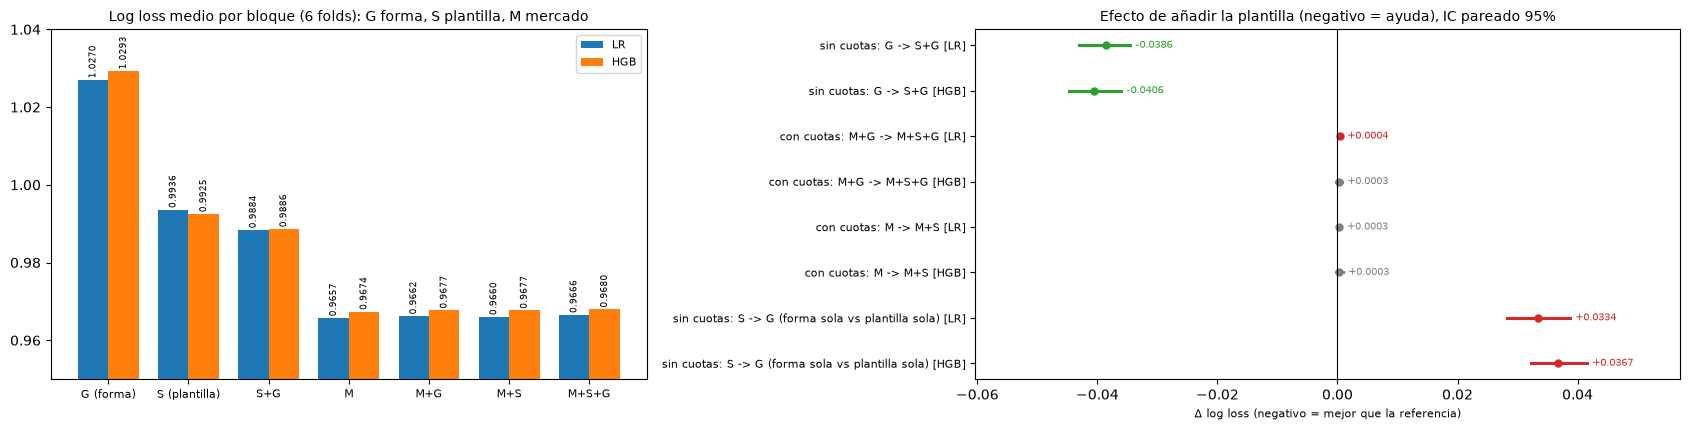

In [14]:
# --- 2) plantilla vs. forma (con y sin cuotas): vectores de perdida por partido
def perdidas(cols, modelo):
    out = np.full(len(y), np.nan)
    for s in FOLDS:
        tr, va = seas < s, seas == s
        fab = lr_t if modelo == 'LR' else hgb_t
        p_ = fab().fit(Xall.loc[tr, cols], y[tr]).predict_proba(Xall.loc[va, cols])
        out[va] = -np.log(np.clip(p_[np.arange(va.sum()), y[va]], 1e-9, 1))
    return out
BL = {'G (forma)': FORMA, 'S (plantilla)': SQ, 'S+G': SQ + FORMA, 'M': MKT, 'M+G': MKT + FORMA, 'M+S': MKT + SQ, 'M+S+G': MKT + SQ + FORMA}
LV = {(b, m): perdidas(c, m) for b, c in BL.items() for m in ('LR', 'HGB')}
ev_m = ~np.isnan(LV[('M', 'LR')])
rng = np.random.default_rng(3)
def dpar(a, b, m):
    d = (LV[(a, m)] - LV[(b, m)])[ev_m]
    bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(1000)]
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
filas = []
for a, b, etiqueta in (('S+G', 'G (forma)', 'sin cuotas: G -> S+G'), ('M+S+G', 'M+G', 'con cuotas: M+G -> M+S+G'), ('M+S', 'M', 'con cuotas: M -> M+S'), ('G (forma)', 'S (plantilla)', 'sin cuotas: S -> G (forma sola vs plantilla sola)')):
    for m in ('LR', 'HGB'):
        d, lo, hi = dpar(a, b, m)
        filas.append(dict(comparacion=etiqueta, modelo=m, delta=d, lo=lo, hi=hi, significativo=bool(hi < 0 or lo > 0)))
tl = pd.DataFrame(filas)
fig, axs = plt.subplots(1, 2, figsize=(17, 4.4), gridspec_kw={'width_ratios': [1.1, 1.3]})
lv_ = pd.DataFrame({m: {b: np.nanmean(LV[(b, m)]) for b in BL} for m in ('LR', 'HGB')}); xs = np.arange(len(lv_)); w_ = 0.38
axs[0].bar(xs - w_ / 2, lv_.LR, w_, color='tab:blue', label='LR'); axs[0].bar(xs + w_ / 2, lv_.HGB, w_, color='tab:orange', label='HGB'); axs[0].set_ylim(0.95, 1.04)
for x_, (a_, b_) in enumerate(zip(lv_.LR, lv_.HGB)): axs[0].text(x_ - w_ / 2, a_ + 0.001, f'{a_:.4f}', ha='center', fontsize=6.5, rotation=90); axs[0].text(x_ + w_ / 2, b_ + 0.001, f'{b_:.4f}', ha='center', fontsize=6.5, rotation=90)
axs[0].set_xticks(xs); axs[0].set_xticklabels(lv_.index, fontsize=8); axs[0].legend(fontsize=8); axs[0].set_title('Log loss medio por bloque (6 folds): G forma, S plantilla, M mercado', fontsize=10)
forest(axs[1], [f'{r.comparacion} [{r.modelo}]' for r in tl.itertuples()], tl.delta.to_numpy(), tl.lo.to_numpy(), tl.hi.to_numpy(), 'Efecto de añadir la plantilla (negativo = ayuda), IC pareado 95%')
plt.tight_layout(); plt.show()

**Hallazgo.** Log loss medio en los 6 folds:

| Bloque | LR | HGB |
|---|---|---|
| G (forma) | 1.0270 | 1.0293 |
| S (plantilla) | 0.9936 | 0.9925 |
| S+G | 0.9884 | 0.9886 |
| M (cuotas) | **0.9657** | 0.9674 |
| M+G | 0.9662 | 0.9677 |
| M+S | 0.9660 | 0.9677 |
| M+S+G | 0.9666 | 0.9680 |

*Diferencia por partido (negativo = ayuda), IC pareado 95%:*

| Comparación | LR | HGB |
|---|---|---|
| Sin cuotas: G → **S+G** | **−0.0386** [−0.0430, −0.0346] | **−0.0406** [−0.0448, −0.0361] |
| Sin cuotas: plantilla sola vs. forma sola (G − S) | +0.0334 [+0.028, +0.039] | +0.0367 [+0.032, +0.042] |
| Con cuotas: M+G → M+S+G | +0.0004 [+0.0000, +0.0007] | +0.0003 [−0.0002, +0.0007] |
| Con cuotas: M → M+S | +0.0003 [−0.0001, +0.0007] | +0.0003 [−0.0002, +0.0009] |

**Respuesta a la pregunta de investigación 2.** **Sí: la plantilla mejora la predicción respecto a solo estadísticas históricas de partido, y por un margen enorme**: sin cuotas, la plantilla sola obtiene 0.9936 contra 1.0270 de la forma sola (la forma de 5 partidos apenas supera al prior, 1.0718), y añadirla a la forma reduce el log loss en 0.039 [−0.043, −0.035]. **Pero esa mejora desaparece por completo en presencia de las cuotas** (Δ ≈ +0.0003, no significativo salvo un pequeño empeoramiento con LR en M+G → M+S+G): las cuotas ya contienen toda la información de la plantilla.

In [15]:
# --- (ii) la plantilla aporta mas al inicio de la temporada?
fechas = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
inicio = fechas.groupby([df['Div'], df['Season']]).transform('min')
semana = ((fechas - inicio).dt.days // 7).to_numpy()
grupos = pd.cut(semana, [-1, 5, 11, 23, 100], labels=['semanas 1-6', 'semanas 7-12', 'semanas 13-24', 'semanas 25+'])
print('Partidos de evaluacion por grupo:', pd.Series(grupos[ev_m]).value_counts().sort_index().to_dict())
def por_grupo(a, b, m):
    d = LV[(a, m)] - LV[(b, m)]
    out = []
    for g in grupos.categories:
        mk_ = ev_m & (grupos == g)
        x = d[mk_]
        bs = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(500)]
        out.append(dict(grupo=g, n=int(mk_.sum()), delta=x.mean(), ic=f'[{np.percentile(bs, 2.5):+.4f}, {np.percentile(bs, 97.5):+.4f}]'))
    return pd.DataFrame(out)
for a, b, et in (('M+S', 'M', 'con cuotas: efecto de anadir plantilla (M+S - M), LR'), ('S+G', 'G (forma)', 'sin cuotas: efecto de anadir plantilla (S+G - G), LR')):
    print(f'\n{et}  [negativo = la plantilla ayuda]')
    print(por_grupo(a, b, 'LR').round(4).to_string(index=False))
# la forma es menos informativa al inicio?
print('\nPerdida del modelo con forma sola (G), por grupo de semanas (LR):')
print(pd.Series({g: np.nanmean(LV[('G (forma)', 'LR')][ev_m & (grupos == g)]) for g in grupos.categories}).round(4).to_string())
print('Perdida del prior-equivalente (mercado crudo), por grupo:')
pm_ = -np.log(np.clip(odds[['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy()[np.arange(len(y)), y], 1e-9, 1))
print(pd.Series({g: float(pm_[ev_m & (grupos == g)].mean()) for g in grupos.categories}).round(4).to_string())

Partidos de evaluacion por grupo: {'semanas 1-6': 2745, 'semanas 7-12': 2561, 'semanas 13-24': 5068, 'semanas 25+': 7810}

con cuotas: efecto de anadir plantilla (M+S - M), LR  [negativo = la plantilla ayuda]
        grupo    n   delta                 ic
  semanas 1-6 2745 -0.0000 [-0.0009, +0.0008]
 semanas 7-12 2561  0.0002 [-0.0006, +0.0011]
semanas 13-24 5068  0.0005 [-0.0002, +0.0011]
  semanas 25+ 7810  0.0003 [-0.0003, +0.0009]

sin cuotas: efecto de anadir plantilla (S+G - G), LR  [negativo = la plantilla ayuda]
        grupo    n   delta                 ic
  semanas 1-6 2745 -0.0513 [-0.0639, -0.0409]
 semanas 7-12 2561 -0.0348 [-0.0456, -0.0241]
semanas 13-24 5068 -0.0357 [-0.0443, -0.0276]
  semanas 25+ 7810 -0.0373 [-0.0433, -0.0308]

Perdida del modelo con forma sola (G), por grupo de semanas (LR):
semanas 1-6      1.0467
semanas 7-12     1.0194
semanas 13-24    1.0292
semanas 25+      1.0211
Perdida del prior-equivalente (mercado crudo), por grupo:
semanas 1-6      0.9757

**Hallazgo.** Partidos por grupo de semanas desde el inicio de cada liga-temporada: 1–6: 2,745; 7–12: 2,561; 13–24: 5,068; 25+: 7,810.

| Grupo | Efecto de añadir la plantilla **con cuotas** (M+S − M) | Efecto **sin cuotas** (S+G − G) |
|---|---|---|
| Semanas 1–6 | −0.0000 [−0.0009, +0.0008] | **−0.0513** [−0.0639, −0.0409] |
| Semanas 7–12 | +0.0002 [−0.0006, +0.0011] | −0.0348 [−0.0456, −0.0241] |
| Semanas 13–24 | +0.0005 [−0.0002, +0.0011] | −0.0357 [−0.0443, −0.0276] |
| Semanas 25+ | +0.0003 [−0.0003, +0.0009] | −0.0373 [−0.0433, −0.0308] |

El modelo con solo forma pierde más al inicio (1.0467 en las semanas 1–6 frente a 1.0194–1.0292 después).

**Respuesta a la hipótesis (ii).**

- **La parte "sobre todo al inicio de la temporada" se cumple, pero solo sin cuotas:** la plantilla aporta un 40% más en las semanas 1–6 (−0.051 frente a −0.035/−0.037), precisamente cuando la forma de los equipos aún no existe.
- **La parte "aportan señal complementaria" no se cumple:** con las cuotas, el efecto de la plantilla es ≈ 0 en **todos** los grupos, incluido el inicio de la temporada. El mercado ya incorpora esa información desde la primera jornada.

## Resumen y siguiente paso

**Preguntas de investigación (informe, sección 1).**

| # | Pregunta | Respuesta | Dónde |
|---|---|---|---|
| 1 | ¿Estable entre temporadas o *concept drift*? | **Estable**; la ventaja sobre el mercado no se degrada; entrenar con ventana corta no ayuda | Paso 10 |
| 2 | ¿La plantilla mejora la predicción frente a solo estadísticas históricas? | **Sí, sin cuotas** (Δ = −0.039, IC [−0.043, −0.035]); **no con cuotas** (Δ ≈ +0.0003) | Paso 10 |
| 3 | ¿MI o PCA preservan mejor la señal? | **MI con cuotas** (−0.014, 6/6 folds); **PCA ≥ MI sin cuotas** (+0.004 a +0.005); reducir casi no mejora a usar todas las variables | Paso 9 |
| 4 | ¿Un ensemble de modelos calibrados detecta *value bets* rentables? | **No**: ROI −8.5% a −14.8% sin cuotas; el ensemble ALL empeora a la LR (+0.0031); nada tiene un IC por encima de 0 | `06_mercado.ipynb` Paso 7; Paso 7 |

**Hipótesis.**

| # | Hipótesis | Veredicto |
|---|---|---|
| (i) | Las cuotas dominan sobre las demás features | **Confirmada** (Pasos 2–5; `06_mercado.ipynb`) |
| (ii) | La plantilla aporta señal complementaria, sobre todo al inicio de la temporada | **Parcial**: la plantilla pesa más al inicio **sin cuotas**, pero **no es complementaria a las cuotas** en ningún momento |
| (iii) | Un modelo mal calibrado puede acertar más pero perder dinero | **No en esa forma** (se prueba en `06_mercado.ipynb`, Paso 8): el modelo perdedor está bien calibrado en promedio y acierta menos; el problema es su calibración condicional donde discrepa del mercado |

**Otros resultados.**

| Pregunta | Respuesta |
|---|---|
| ¿Los modelos superan al mercado crudo? | Solo la **LR sobre cuotas**, por 0.0007 (recalibración); SVM, XGBoost, MLP, HGB y el ensemble son significativamente peores |
| ¿Aportan las habilidades individuales (Stübinger et al.)? | **No:** empeoran el log loss y no mejoran al mercado al apilarlas |
| ¿Importa la temporada 2024/25 (snapshot de fin de temporada)? | Ya no interviene: 2024/25 y 2025/26 son el test holdout (`08_modelo_final.ipynb`, Paso 8) |
| ¿Qué modelo se recomienda? | **LR sobre `MKT_logit`, `MKT_pD`, `MKT_margin`**: mejor log loss (0.9657), RPS (0.1951) y calibración (ECE 0.0077) |

**Sobre los hiperparámetros.** Los de los Pasos 2–5 se fijaron de forma conservadora porque allí solo se compara el aporte de cada bloque. La **selección formal** (rejilla, ventana de ajuste disjunta de los folds de evaluación y desempate por simplicidad) está en los Pasos 6a (LR, HGB, RF) y 6 (SVM, XGBoost, MLP) de este cuaderno; los valores quedan en `hiperparametros.json` y `hiperparametros_modelos.json`.

**Siguiente.** Actualizar el informe (secciones 3–9) con estos resultados y corregir la cita del paper.

## Ampliaciones posteriores

Esta evaluación se amplió en los cuadernos `05` a `08`, que **no cambian ninguna conclusión** de este notebook (el `08_modelo_final` reemplaza a la LR de tres variables por una de dos sobre Pinnacle: log loss 0.9653 frente a 0.9657 en validación, y 0.9651 en el test holdout):

- `07_evaluacion.ipynb`: curvas ROC y AUC, ECE de igual ancho y de igual masa, MCE, recalibración, comparación con K-fold y *leave-one-season-out*, *bootstrap* **por bloques** (los IC son solo ×1.00 más anchos que los de partidos sueltos) y corrección de Benjamini–Hochberg (10 de 11 contrastes significativos).
- `03_preprocesamiento.ipynb`: evidencia empírica de cada decisión de preprocesamiento, features de Elo/EWMA (mejoran el benchmark sin cuotas en 0.0068; con cuotas no aportan) y PSI entre temporadas (`MKT_margin` es no estacionaria).
- `05_hiperparametros.ipynb`: validación anidada (reproduce el log loss con ±0.0001), rejillas extendidas (el óptimo de los árboles es de profundidad 1), SVM con probabilidades corregidas (la `P(empate)` del `SVC(probability=True)` original está invertida: AUC 0.44) y ensemble de regresión con SVR (RMSE 1.6708 frente a 1.6704).

**Dos precisiones sobre este notebook.** (1) El ensemble `ALL` del Paso 4 no incluye el SVM/SVR del paper original; agregarlo no cambia el RMSE. (2) La mejora de XGBoost con rejillas extendidas (−0.0017) no alcanza a la LR sobre cuotas.